# **Rice Leaf Disease Detector — MobileNetV4**




## 0 · Setup & CONFIG


In [ ]:
# ============================== CONFIG (edit here) ==============================
QUICK_RUN = False

DATA_MODE = 'drive'
DRIVE_DATASET_DIR = '/content/drive/MyDrive/Rice_Leaf_Disease_Project/Rice Leaf Disease'
LOCAL_DIR         = '/content/rice_leaf_dataset'
KAGGLE_DATASET    = ''
COPY_TO_LOCAL     = True

DATASET_SOURCE_NOTE = ''

# ======================================================
#                     MODELS
# ======================================================
MODEL_NAME        = 'mobilenetv4_conv_medium.e500_r256_in1k'
SECOND_MODEL_NAME = 'mobilenetv3_large_100.ra_in1k'

# ======================================================
#                     TRAINING
# ======================================================
IMG_SIZE         = 256
BATCH_SIZE       = 32
EPOCHS_BASELINE  = 4
EPOCHS_FINETUNE  = 24
SEED             = 42
RUN_GRADIO       = False

if QUICK_RUN:
    EPOCHS_BASELINE, EPOCHS_FINETUNE = 2, 2
    PER_CLASS_CAP = 40
else:
    PER_CLASS_CAP = None
print('QUICK_RUN =', QUICK_RUN)

QUICK_RUN = False


In [ ]:
!pip install -q -U timm tqdm scikit-learn seaborn

In [ ]:
import os, sys, json, random, hashlib, time, copy, shutil, zipfile, warnings
from google.colab import drive
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
import torch, torch.nn as nn, torch.nn.functional as F
import timm
warnings.filterwarnings('ignore')

drive.mount('/content/drive')
BASE = Path('/content/drive/MyDrive/Rice_Leaf_Disease_Project') if Path('/content').exists() else Path('./colab_work')
OUT_DIR, MODEL_DIR = BASE / 'outputs', BASE / 'models'
for d in (OUT_DIR, MODEL_DIR): d.mkdir(parents=True, exist_ok=True)

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
NUM_WORKERS = 2

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ['PYTHONHASHSEED'] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()
sns.set_theme(style='whitegrid', context='notebook')
print('device:', DEVICE, '| outputs ->', OUT_DIR)

Mounted at /content/drive
device: cpu | outputs -> /content/drive/MyDrive/Rice_Leaf_Disease_Project/outputs


# **Week 1: Machine LEarning Formulation and Project Planning**

In [ ]:
# ======================================================
#                   WEEK 1 INITIATION
# ======================================================
print('Python  :', sys.version.split()[0])
print('PyTorch :', torch.__version__)
print('timm    :', timm.__version__)
print('GPU     :', torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else 'NONE')
v4 = timm.list_models('mobilenetv4*', pretrained=True)
print('\nMobileNetV4 pretrained variants in this timm version:')
for m in v4: print('   ', m)
assert any(m.startswith('mobilenetv4_conv_medium') for m in v4), 'timm too old -> !pip install -U timm'
x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
m_test = timm.create_model(MODEL_NAME, pretrained=False, num_classes=8).eval()
with torch.no_grad(): print('\nTest forward pass OK ->', tuple(m_test(x).shape))
del m_test
print('Week-1 test cell executed')

Python  : 3.13.18
PyTorch : 2.14.1+cpu
timm    : 1.0.31
GPU     : NONE

MobileNetV4 pretrained variants in this timm version:
    mobilenetv4_conv_aa_large.e230_r384_in12k
    mobilenetv4_conv_aa_large.e230_r384_in12k_ft_in1k
    mobilenetv4_conv_aa_large.e230_r448_in12k_ft_in1k
    mobilenetv4_conv_aa_large.e600_r384_in1k
    mobilenetv4_conv_blur_medium.e500_r224_in1k
    mobilenetv4_conv_large.e500_r256_in1k
    mobilenetv4_conv_large.e600_r384_in1k
    mobilenetv4_conv_medium.e180_ad_r384_in12k
    mobilenetv4_conv_medium.e180_r384_in12k
    mobilenetv4_conv_medium.e250_r384_in12k
    mobilenetv4_conv_medium.e250_r384_in12k_ft_in1k
    mobilenetv4_conv_medium.e500_r224_in1k
    mobilenetv4_conv_medium.e500_r256_in1k
    mobilenetv4_conv_small.e1200_r224_in1k
    mobilenetv4_conv_small.e2400_r224_in1k
    mobilenetv4_conv_small.e3600_r256_in1k
    mobilenetv4_conv_small_050.e3000_r224_in1k
    mobilenetv4_hybrid_large.e600_r384_in1k
    mobilenetv4_hybrid_large.ix_e600_r384_in1k
   

---
# WEEK 2 · Dataset Preparation and Feature Engineering


## 2.1 Load the dataset

In [ ]:
if DATA_MODE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = Path(DRIVE_DATASET_DIR)
elif DATA_MODE == 'upload_zip':
    from google.colab import files
    up = files.upload()
    DATA_ROOT = Path('/content/rice_upload'); DATA_ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(list(up.keys())[0]) as z: z.extractall(DATA_ROOT)
elif DATA_MODE == 'kaggle':
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'], check=True)
    import kagglehub
    DATA_ROOT = Path(kagglehub.dataset_download(KAGGLE_DATASET))
else:
    DATA_ROOT = Path(LOCAL_DIR)

assert DATA_ROOT.exists(), f'Dataset folder not found: {DATA_ROOT}  (check DATA_MODE / paths in CONFIG)'

def find_subdir(root, name, max_depth=3):
    frontier = [Path(root)]
    for _ in range(max_depth + 1):
        nxt = []
        for d in frontier:
            for p in sorted(d.iterdir()):
                if p.is_dir():
                    if p.name.lower() == name.lower(): return p
                    nxt.append(p)
        frontier = nxt
    return None

ORIG_DIR = find_subdir(DATA_ROOT, 'Orig')
AUG_DIR  = find_subdir(DATA_ROOT, 'Altered')
assert ORIG_DIR is not None, "Could not find a folder named 'Original' inside the dataset folder."
print('Original  :', ORIG_DIR)
print('Augmented :', AUG_DIR)

if COPY_TO_LOCAL and str(ORIG_DIR).startswith('/content/drive') or (COPY_TO_LOCAL and DATA_MODE == 'kaggle'):
    local_orig = Path('/content/rice_local/Original')
    if not local_orig.exists():
        print('Copying Original/ to local disk')
        shutil.copytree(ORIG_DIR, local_orig)
    ORIG_DIR = local_orig
    print('Using local copy:', ORIG_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Original  : /content/drive/MyDrive/Rice_Leaf_Disease_Project/Rice Leaf Disease/Orig
Augmented : /content/drive/MyDrive/Rice_Leaf_Disease_Project/Rice Leaf Disease/Altered
Copying Original/ to local disk
Using local copy: /content/rice_local/Original


In [ ]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}

def list_images(base, subset):
    rows = []
    for cls_dir in sorted([d for d in Path(base).iterdir() if d.is_dir()]):
        for f in cls_dir.rglob('*'):
            if f.is_file() and f.suffix.lower() in IMG_EXT:
                rows.append({'path': str(f), 'class_name': cls_dir.name, 'subset': subset})
    return pd.DataFrame(rows, columns=['path', 'class_name', 'subset'])

df_orig = list_images(ORIG_DIR, 'Original Images')
df_aug  = list_images(AUG_DIR, 'Augmented Images') if AUG_DIR else pd.DataFrame(columns=['path', 'class_name', 'subset'])
assert len(df_orig) > 0, 'No images found in Original/ - check the folder structure Original/<class>/<image>'

if PER_CLASS_CAP:
    df_orig = df_orig.groupby('class_name', group_keys=False).head(PER_CLASS_CAP).reset_index(drop=True)

counts = (pd.concat([df_orig, df_aug]).groupby(['class_name', 'subset']).size().unstack(fill_value=0))
print('Images per class and subset:'); display(counts)
print('Total  Original:', len(df_orig), '| Augmented:', len(df_aug))

Images per class and subset:


subset,Augmented Images,Original Images
class_name,,
Healthy,511,910
bacterial_leaf_blight,536,958
brown_spot,810,1012
leaf_blast,929,826
leaf_scald,560,703
narrow_brown_spot,353,884
neck_blast,0,658
rice_hispa,664,974
sheath_blight,825,878


Total  Original: 8359 | Augmented: 5188


## 2.2 Inspect data types, missing values, corrupt files

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def inspect_image(path):
    try:
        with Image.open(path) as im: im.verify()
        with Image.open(path) as im: w, h = im.size; mode = im.mode
        with open(path, 'rb') as fh: md5 = hashlib.md5(fh.read()).hexdigest()
        return dict(width=w, height=h, mode=mode, md5=md5, readable=True, size_kb=os.path.getsize(path) / 1024)
    except Exception:
        return dict(width=np.nan, height=np.nan, mode=None, md5=None, readable=False, size_kb=np.nan)

def inspect_df(df):
    with ThreadPoolExecutor(16) as ex:
        info = list(tqdm(ex.map(inspect_image, df.path), total=len(df), desc='inspecting'))
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(info)], axis=1)

df = inspect_df(df_orig)
print('Shape (rows, cols):', df.shape)
print('\nData types:'); display(df.dtypes.to_frame('dtype'))
print('\nMissing values per column:'); display(df.isna().sum().to_frame('n_missing'))
print('Colour modes:', df['mode'].value_counts(dropna=False).to_dict())
print('Unreadable / corrupt images:', int((~df.readable).sum()))

inspecting:   0%|          | 0/8359 [00:00<?, ?it/s]

Shape (rows, cols): (8359, 9)

Data types:


,dtype
path,object
class_name,object
subset,object
width,int64
height,int64
mode,object
md5,object
readable,bool
size_kb,float64



Missing values per column:


,n_missing
path,0
class_name,0
subset,0
width,0
height,0
mode,0
md5,0
readable,0
size_kb,0


Colour modes: {'RGB': 8358, 'P': 1}
Unreadable / corrupt images: 0


## 2.3 Duplicates, label conflicts & "shortcut" check

Exact duplicate files (same bytes): 158
Same image filed under DIFFERENT classes (label conflict): 1 hashes


,step,rows_after
0,start,8359
1,drop unreadable,8359
2,drop label-conflict images,8357
3,drop exact duplicates,8200



Classes (index -> name): {0: 'Healthy', 1: 'bacterial_leaf_blight', 2: 'brown_spot', 3: 'leaf_blast', 4: 'leaf_scald', 5: 'narrow_brown_spot', 6: 'neck_blast', 7: 'rice_hispa', 8: 'sheath_blight', 9: 'tungro'}
Largest/smallest class ratio = 1.76 -> imbalanced, use macro-F1 (+ class weights test in Week 5)


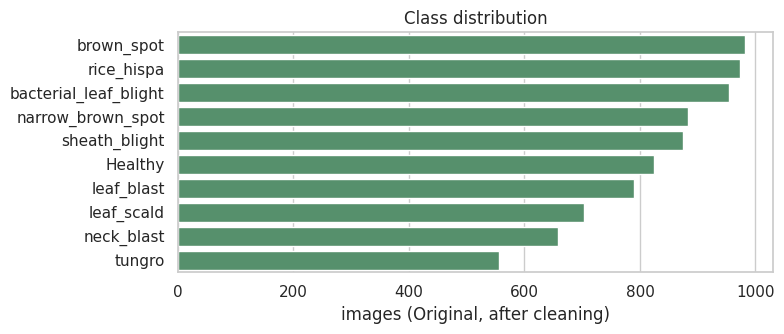

In [ ]:
ok = df[df.readable]
n_dup = int(ok.duplicated('md5', keep='first').sum())
by_hash = ok.groupby('md5').class_name.nunique()
conflict_hashes = by_hash[by_hash > 1].index
print(f'Exact duplicate files (same bytes): {n_dup}')
print(f'Same image filed under DIFFERENT classes (label conflict): {len(conflict_hashes)} hashes')

# ==========================================
#                 CLEANINMG
# ==========================================
log = [('start', len(df))]
df_clean = df[df.readable].copy();                                  log.append(('drop unreadable', len(df_clean)))
df_clean = df_clean[~df_clean.md5.isin(conflict_hashes)];           log.append(('drop label-conflict images', len(df_clean)))
df_clean = df_clean.drop_duplicates('md5', keep='first');           log.append(('drop exact duplicates', len(df_clean)))
df_clean = df_clean.reset_index(drop=True)
display(pd.DataFrame(log, columns=['step', 'rows_after']))

# ==========================================
#                 ENCODING
# ==========================================
CLASS_NAMES = sorted(df_clean.class_name.unique())
NUM_CLASSES = len(CLASS_NAMES)
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
df_clean['label'] = df_clean.class_name.map(class_to_idx)
print('\nClasses (index -> name):', dict(enumerate(CLASS_NAMES)))
assert NUM_CLASSES == 10, f'Expected 8 classes, found {NUM_CLASSES}: {CLASS_NAMES}'

cnt = df_clean.class_name.value_counts()
IMBALANCE_RATIO = cnt.max() / cnt.min()
print(f'Largest/smallest class ratio = {IMBALANCE_RATIO:.2f}', '-> imbalanced, use macro-F1 (+ class weights test in Week 5)' if IMBALANCE_RATIO > 1.5 else '-> reasonably balanced')

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=cnt.values, y=cnt.index, ax=ax, color='#4c9a6a'); ax.set_xlabel('images (Original, after cleaning)'); ax.set_ylabel('')
ax.set_title('Class distribution'); plt.tight_layout(); plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
df_clean['aspect_ratio'] = df_clean.width / df_clean.height
df_clean['megapixels']   = df_clean.width * df_clean.height / 1e6
Xmeta = df_clean[['width', 'height', 'aspect_ratio', 'size_kb']].values
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
acc_meta = cross_val_score(RandomForestClassifier(150, random_state=SEED, n_jobs=-1), Xmeta, df_clean.label, cv=cv).mean()
print(f'Accuracy from metadata only: {acc_meta:.1%}   (chance = {1/NUM_CLASSES:.1%}, majority class = {cnt.max()/cnt.sum():.1%})')
if acc_meta > 0.5:
    print('images of different classes were probably taken/saved differently.\n'
          '    Resizing every image to the same square size removes the size cue')
display(df_clean.groupby('class_name')[['width', 'height', 'size_kb']].agg(['min', 'median', 'max']).round(1))

Accuracy from metadata only: 43.6%   (chance = 10.0%, majority class = 12.0%)


width               height               size_kb  \
                        min  median   max    min  median   max     min   
class_name                                                               
Healthy                 427  1600.0  4000    441  1600.0  3840    44.0   
bacterial_leaf_blight   183  1600.0  1600    178  1600.0  1600     6.9   
brown_spot             1029  1600.0  1600   1200  1600.0  1600    60.2   
leaf_blast             1200  1600.0  1600   1200  1200.0  1600    57.2   
leaf_scald              545  1600.0  1600    982  1600.0  1600    54.3   
narrow_brown_spot      1200  1600.0  1600   1200  1600.0  1600    56.3   
neck_blast             3120  3120.0  3120   3120  3120.0  3120  1024.9   
rice_hispa              431  1600.0  4000   1086  1200.0  3000    43.6   
sheath_blight           390  1600.0  4000    469  1200.0  3264    32.7   
tungro                  211   340.0  1970    209   344.5  1920    13.6   

                                       
                       median     max  
class_name                             
Healthy                 212.7  6601.0  
bacterial_leaf_blight   105.4  1408.5  
brown_spot              137.9  1227.7  
leaf_blast              208.3  1415.0  
leaf_scald               81.8  1318.8  
narrow_brown_spot       114.9  1361.5  
neck_blast             1397.7  2876.1  
rice_hispa              171.3  1828.9  
sheath_blight           243.3  6108.1  
tungro                   16.9   233.2

In [ ]:
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(10, 2.3 * NUM_CLASSES))
for r, c in enumerate(CLASS_NAMES):
    sub = df_clean[df_clean.class_name == c]
    pick = sub.sample(min(4, len(sub)), random_state=SEED).path.tolist()
    for k in range(4):
        ax = axes[r, k]; ax.axis('off')
        if k < len(pick):
            ax.imshow(Image.open(pick[k]).convert('RGB'))
            if k == 0: ax.set_title(c, loc='left', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

---
# WEEK 3 · Initial Machine Learning Model Development

## 3.1 Preprocessing and 3.2 Split

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.model_selection import train_test_split

# ==========================================
#             3.2 SPLITTING
# ==========================================
train_df, temp_df = train_test_split(df_clean, test_size=0.30, stratify=df_clean.label, random_state=SEED)
val_df,   test_df = train_test_split(temp_df,  test_size=0.50, stratify=temp_df.label,  random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

# ==========================================
#             CHECK DATA LOST
# ==========================================
for a, b, name in [(train_df, val_df, 'train/val'), (train_df, test_df, 'train/test'), (val_df, test_df, 'val/test')]:
    assert set(a.path).isdisjoint(b.path) and set(a.md5).isdisjoint(b.md5), f'LEAKAGE between {name}!'
print('no overlap between train / val / test')
split_table = pd.DataFrame({'train': train_df.class_name.value_counts(), 'val': val_df.class_name.value_counts(),
                            'test': test_df.class_name.value_counts()}).fillna(0).astype(int)
split_table.loc['TOTAL'] = split_table.sum(); display(split_table)

# ==========================================
#             3.1 PREPROCESSING
# ==========================================
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

def make_transforms(aug='basic'):
    norm = T.Normalize(MEAN, STD)
    eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), norm])
    if aug == 'basic':
        train_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                              T.ToTensor(), norm])
    else:
        train_tf = T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
                              T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(25),
                              T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
                              T.ToTensor(), norm, T.RandomErasing(p=0.2, scale=(0.02, 0.1))])
    return train_tf, eval_tf

EVAL_TF = make_transforms()[1]

class RiceDS(Dataset):
    def __init__(self, df, tf): self.paths, self.labels, self.tf = df.path.tolist(), df.label.tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert('RGB')), self.labels[i]

def make_loaders(aug='basic', batch_size=BATCH_SIZE):
    tr_tf, ev_tf = make_transforms(aug)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'), persistent_workers=NUM_WORKERS > 0)
    return (DataLoader(RiceDS(train_df, tr_tf), batch_size, shuffle=True, drop_last=True, **kw),
            DataLoader(RiceDS(val_df,   ev_tf), batch_size * 2, shuffle=False, **kw),
            DataLoader(RiceDS(test_df,  ev_tf), batch_size * 2, shuffle=False, **kw))
print('preprocessing ready')

no overlap between train / val / test


,train,val,test
class_name,,,
brown_spot,687,147,147
rice_hispa,682,146,146
bacterial_leaf_blight,668,144,143
narrow_brown_spot,619,132,133
sheath_blight,612,131,131
Healthy,577,124,124
leaf_blast,553,119,118
leaf_scald,492,105,106
neck_blast,461,98,99


preprocessing ready


## 3.3 Model, training loop and evaluation helpers

In [ ]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, log_loss, roc_auc_score, top_k_accuracy_score)

def build_model(name=MODEL_NAME, pretrained=True, freeze_backbone=False, drop_rate=0.2):
    m = timm.create_model(name, pretrained=pretrained, num_classes=NUM_CLASSES, drop_rate=drop_rate)
    m.cfg_name = name
    if freeze_backbone:
        for p in m.parameters(): p.requires_grad = False
        for p in m.get_classifier().parameters(): p.requires_grad = True
    return m.to(DEVICE)

def set_train_mode(model, frozen):
    model.train()
    if frozen:
        for mod in model.modules():
            if isinstance(mod, nn.modules.batchnorm._BatchNorm): mod.eval()

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            out = model(x.to(DEVICE, non_blocking=True))
        ps.append(F.softmax(out.float(), 1).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def metrics_summary(y, p):
    pred = p.argmax(1)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    out = dict(accuracy=accuracy_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred),
               macro_precision=pr, macro_recall=rc, macro_f1=f1,
               weighted_f1=f1_score(y, pred, average='weighted', zero_division=0),
               top3_acc=top_k_accuracy_score(y, p, k=3, labels=list(range(NUM_CLASSES))),
               log_loss=log_loss(y, p, labels=list(range(NUM_CLASSES))))
    try: out['roc_auc_ovr'] = roc_auc_score(y, p, multi_class='ovr', labels=list(range(NUM_CLASSES)))
    except ValueError: out['roc_auc_ovr'] = float('nan')
    return out

def fit(model, train_loader, val_loader, epochs, lr_head=1e-3, lr_backbone=None, weight_decay=1e-4,
        label_smoothing=0.0, class_weights=None, frozen=False, patience=5, tag='model'):
    head_params = [p for p in model.get_classifier().parameters() if p.requires_grad]
    head_ids = {id(p) for p in head_params}
    back_params = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [{'params': head_params, 'lr': lr_head}]
    if back_params: groups.append({'params': back_params, 'lr': lr_backbone or lr_head / 10})
    opt = torch.optim.AdamW(groups, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g['lr'] for g in groups],
                                                total_steps=epochs * len(train_loader), pct_start=0.15)
    cw = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE) if class_weights is not None else None
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=label_smoothing)
    try: scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    hist, best_f1, best_state, bad = [], -1.0, None, 0
    for ep in range(1, epochs + 1):
        set_train_mode(model, frozen); t0 = time.time(); tl = tc = n = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        yv, pv = predict(model, val_loader); mv = metrics_summary(yv, pv)
        row = dict(epoch=ep, train_loss=tl / n, train_acc=tc / n, val_loss=mv['log_loss'], val_acc=mv['accuracy'],
                   val_macro_f1=mv['macro_f1'], secs=time.time() - t0)
        hist.append(row)
        print(f"[{tag}] ep {ep:02d}/{epochs}  train loss {row['train_loss']:.3f} acc {row['train_acc']:.3f} | "
              f"val loss {row['val_loss']:.3f} acc {row['val_acc']:.3f} macroF1 {row['val_macro_f1']:.3f} | {row['secs']:.0f}s")
        if mv['macro_f1'] > best_f1:
            best_f1, bad = mv['macro_f1'], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: print('early stopping'); break
    model.load_state_dict(best_state)
    torch.save({'state_dict': best_state, 'class_names': CLASS_NAMES, 'model_name': model.cfg_name,
                'img_size': IMG_SIZE}, MODEL_DIR / f'{tag}.pt')
    return pd.DataFrame(hist), model

def n_params_m(m): return sum(p.numel() for p in m.parameters()) / 1e6

@torch.no_grad()
def latency_ms(model, runs=30):
    model.eval(); x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    for _ in range(5): model(x)
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(runs): model(x)
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t0) / runs * 1000

def save_predictions(df, p, name):
    out = df[['path', 'class_name', 'label']].copy()
    out['pred_label'] = p.argmax(1); out['pred_class'] = [CLASS_NAMES[i] for i in out.pred_label]
    out['confidence'] = p.max(1); out['correct'] = out.label == out.pred_label
    for i, c in enumerate(CLASS_NAMES): out[f'p_{c}'] = p[:, i]
    path = OUT_DIR / f'{name}.csv'; out.to_csv(path, index=False); return out, path

RESULTS, HISTORY, PROBS = {}, {}, {}
print('helpers ready')

helpers ready


## 3.4 Train the baseline

In [ ]:
set_seed()
train_loader, val_loader, test_loader = make_loaders('basic')
baseline = build_model(MODEL_NAME, pretrained=True, freeze_backbone=True)
print(f'MobileNetV4 total params: {n_params_m(baseline):.2f} M | trainable: '
      f'{sum(p.numel() for p in baseline.parameters() if p.requires_grad)/1e6:.3f} M')
hist_b, baseline = fit(baseline, train_loader, val_loader, epochs=EPOCHS_BASELINE, lr_head=2e-3,
                       frozen=True, tag='v4_baseline_frozen')
HISTORY['v4_baseline_frozen'] = hist_b

model.safetensors: reconstructing file:   0%|          |  0.00B / 39.2MB            

model.safetensors: downloading bytes:           |  0.00B            

MobileNetV4 total params: 8.45 M | trainable: 0.013 M
[v4_baseline_frozen] ep 01/4  train loss 4.592 acc 0.288 | val loss 1.427 acc 0.593 macroF1 0.616 | 857s
[v4_baseline_frozen] ep 02/4  train loss 1.757 acc 0.582 | val loss 1.021 acc 0.707 macroF1 0.707 | 847s
[v4_baseline_frozen] ep 03/4  train loss 1.344 acc 0.646 | val loss 0.881 acc 0.739 macroF1 0.746 | 860s
[v4_baseline_frozen] ep 04/4  train loss 1.254 acc 0.666 | val loss 0.862 acc 0.743 macroF1 0.746 | 851s


## 3.5 Initial predictions (saved to CSV)

In [ ]:
yv, pv = predict(baseline, val_loader); yt, pt = predict(baseline, test_loader)
PROBS['v4_baseline_frozen'] = dict(val=pv, test=pt)
RESULTS['v4_baseline_frozen'] = dict(model=MODEL_NAME, setup='frozen backbone, head only', params_M=n_params_m(baseline),
                                     latency_ms=latency_ms(baseline), val=metrics_summary(yv, pv), test=metrics_summary(yt, pt))
pred_df, path = save_predictions(test_df, pt, 'predictions_test_v4_baseline_frozen')
print('saved ->', path)
print(f"Baseline TEST accuracy {RESULTS['v4_baseline_frozen']['test']['accuracy']:.3f} | macro-F1 {RESULTS['v4_baseline_frozen']['test']['macro_f1']:.3f}")
display(pred_df.head())

saved -> /content/drive/MyDrive/Rice_Leaf_Disease_Project/outputs/predictions_test_v4_baseline_frozen.csv
Baseline TEST accuracy 0.744 | macro-F1 0.749


,path,class_name,label,pred_label,pred_class,confidence,correct,p_Healthy,p_bacterial_leaf_blight,p_brown_spot,p_leaf_blast,p_leaf_scald,p_narrow_brown_spot,p_neck_blast,p_rice_hispa,p_sheath_blight,p_tungro
0,/content/rice_local/Original/neck_blast/neck_b...,neck_blast,6,6,neck_blast,0.977466,True,0.000214,2.186198e-02,0.000023,0.000012,0.000196,0.000050,9.774659e-01,0.000043,0.000131,3.419926e-06
1,/content/rice_local/Original/sheath_blight/she...,sheath_blight,8,8,sheath_blight,0.729003,True,0.001235,1.293472e-03,0.000106,0.266236,0.000048,0.000198,5.177701e-07,0.001880,0.729003,3.603679e-07
2,/content/rice_local/Original/sheath_blight/she...,sheath_blight,8,8,sheath_blight,0.534639,True,0.000171,1.733826e-02,0.007932,0.002398,0.437174,0.000273,5.999082e-07,0.000061,0.534639,1.397024e-05
3,/content/rice_local/Original/Healthy/healthy84...,Healthy,0,0,Healthy,0.866359,True,0.866359,7.483341e-07,0.052707,0.072947,0.000008,0.001444,5.812216e-06,0.006397,0.000091,4.167324e-05
4,/content/rice_local/Original/sheath_blight/She...,sheath_blight,8,0,Healthy,0.509864,False,0.509864,5.166605e-04,0.038637,0.012631,0.010651,0.064755,9.619863e-02,0.021440,0.020901,2.244066e-01


---
# WEEK 4 · Model Evaluation and Performance Comparison

                       precision    recall  f1-score   support

              Healthy      0.822     0.782     0.802       124
bacterial_leaf_blight      0.743     0.727     0.735       143
           brown_spot      0.730     0.680     0.704       147
           leaf_blast      0.667     0.424     0.518       118
           leaf_scald      0.784     0.651     0.711       106
    narrow_brown_spot      0.594     0.617     0.605       133
           neck_blast      0.970     0.990     0.980        99
           rice_hispa      0.701     0.897     0.787       146
        sheath_blight      0.671     0.840     0.746       131
               tungro      0.902     0.892     0.897        83

             accuracy                          0.744      1230
            macro avg      0.758     0.750     0.749      1230
         weighted avg      0.746     0.744     0.739      1230



,accuracy,balanced_acc,macro_precision,macro_recall,macro_f1,weighted_f1,top3_acc,log_loss,roc_auc_ovr
test,0.7439,0.7499,0.7584,0.7499,0.7485,0.7391,0.9301,0.8307,0.9633


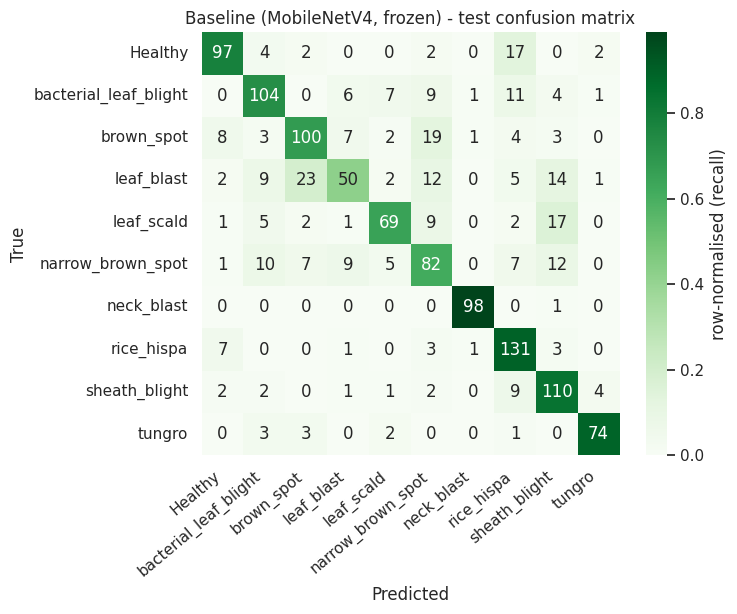

In [ ]:
# ==========================================
#             4.1 METRIX
# ==========================================
yt, pt = test_df.label.values, PROBS['v4_baseline_frozen']['test']
print(classification_report(yt, pt.argmax(1), labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES, digits=3, zero_division=0))
display(pd.Series(RESULTS['v4_baseline_frozen']['test']).round(4).to_frame('test').T)

def plot_cm(y, p, title):
    cm = confusion_matrix(y, p.argmax(1), labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(7.5, 6.3))
    sns.heatmap(cmn, annot=cm, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cbar_kws={'label': 'row-normalised (recall)'}, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
    plt.xticks(rotation=40, ha='right'); plt.tight_layout(); plt.show(); return cm

def top_confusions(cm, k=5):
    off = cm.copy(); np.fill_diagonal(off, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:k], off.shape))[0]
    return [(CLASS_NAMES[i], CLASS_NAMES[j], int(off[i, j])) for i, j in idx if off[i, j] > 0]

cm_base = plot_cm(yt, pt, 'Baseline (MobileNetV4, frozen) - test confusion matrix')

In [ ]:
# ==========================================
#             4.2 INTERPRETATION
# ==========================================
def interpret(y, p, name):
    pred = p.argmax(1); rep = classification_report(y, pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    f1s = pd.Series({c: rep[c]['f1-score'] for c in CLASS_NAMES}).sort_values()
    rec = pd.Series({c: rep[c]['recall'] for c in CLASS_NAMES})
    cm = confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    lines = [f'**{name}** reaches {accuracy_score(y, pred):.1%} accuracy and macro-F1 {f1_score(y, pred, average="macro"):.3f} on the test set.',
             f'Strongest class: **{f1s.index[-1]}** (F1 {f1s.iloc[-1]:.2f}); weakest: **{f1s.index[0]}** (F1 {f1s.iloc[0]:.2f}).']
    conf = top_confusions(cm, 3)
    if conf: lines.append('Most frequent mix-ups: ' + '; '.join(f'{a} -> {b} ({n}x)' for a, b, n in conf) + '.')
    h = CLASS_NAMES.index('Healthy Rice Leaf') if 'Healthy Rice Leaf' in CLASS_NAMES else None
    if h is not None:
        missed = cm[:, h].sum() - cm[h, h]
        lines.append(f'{missed} diseased leaf image(s) were called "Healthy" (the dangerous error: a sick plant is left untreated).')
    lines.append('Macro-F1 target of 0.90 is ' + ('**met**.' if f1_score(y, pred, average='macro') >= 0.90 else '**not yet met**'))
    display(Markdown('\n\n'.join('- ' + l for l in lines)))
interpret(yt, pt, 'Baseline (MobileNetV4 frozen)')

- **Baseline (MobileNetV4 frozen)** reaches 74.4% accuracy and macro-F1 0.749 on the test set.

- Strongest class: **neck_blast** (F1 0.98); weakest: **leaf_blast** (F1 0.52).

- Most frequent mix-ups: leaf_blast -> brown_spot (23x); brown_spot -> narrow_brown_spot (19x); leaf_scald -> sheath_blight (17x).

- Macro-F1 target of 0.90 is **not yet met**

## 4.3 Second model for comparison — MobileNetV3-Large

In [ ]:
set_seed()
m3 = build_model(SECOND_MODEL_NAME, pretrained=True, freeze_backbone=True)
hist_3, m3 = fit(m3, train_loader, val_loader, epochs=EPOCHS_BASELINE, lr_head=2e-3, frozen=True, tag='v3_frozen')
HISTORY['v3_frozen'] = hist_3
yv, pv3 = predict(m3, val_loader); yt, pt3 = predict(m3, test_loader)
PROBS['v3_frozen'] = dict(val=pv3, test=pt3)
RESULTS['v3_frozen'] = dict(model=SECOND_MODEL_NAME, setup='frozen backbone, head only', params_M=n_params_m(m3),
                            latency_ms=latency_ms(m3), val=metrics_summary(yv, pv3), test=metrics_summary(yt, pt3))

def results_table(keys=None):
    rows = []
    for k, r in RESULTS.items():
        if keys and k not in keys: continue
        rows.append({'run': k, 'model': r['model'].split('.')[0], 'setup': r['setup'], 'params_M': round(r['params_M'], 2),
                     'latency_ms': round(r['latency_ms'], 1), 'val_macroF1': round(r['val']['macro_f1'], 4),
                     'test_acc': round(r['test']['accuracy'], 4), 'test_macroF1': round(r['test']['macro_f1'], 4),
                     'test_top3': round(r['test']['top3_acc'], 4), 'test_logloss': round(r['test']['log_loss'], 4)})
    return pd.DataFrame(rows)
display(results_table())
interpret(yt, pt3, 'MobileNetV3-Large (frozen)')

[v3_frozen] ep 01/4  train loss 2.804 acc 0.375 | val loss 0.900 acc 0.702 macroF1 0.699 | 618s
[v3_frozen] ep 02/4  train loss 0.950 acc 0.709 | val loss 0.578 acc 0.799 macroF1 0.803 | 652s
[v3_frozen] ep 03/4  train loss 0.708 acc 0.775 | val loss 0.506 acc 0.820 macroF1 0.824 | 660s
[v3_frozen] ep 04/4  train loss 0.666 acc 0.786 | val loss 0.496 acc 0.822 macroF1 0.826 | 653s


,run,model,setup,params_M,latency_ms,val_macroF1,test_acc,test_macroF1,test_top3,test_logloss
0,v4_baseline_frozen,mobilenetv4_conv_medium,"frozen backbone, head only",8.45,57.4,0.7463,0.7439,0.7485,0.9301,0.8307
1,v3_frozen,mobilenetv3_large_100,"frozen backbone, head only",4.21,30.7,0.8256,0.8089,0.8117,0.9610,0.5369


- **MobileNetV3-Large (frozen)** reaches 80.9% accuracy and macro-F1 0.812 on the test set.

- Strongest class: **neck_blast** (F1 0.99); weakest: **leaf_blast** (F1 0.58).

- Most frequent mix-ups: leaf_blast -> brown_spot (23x); brown_spot -> narrow_brown_spot (14x); leaf_blast -> narrow_brown_spot (12x).

- Macro-F1 target of 0.90 is **not yet met**

## 4.4 Save outputs

In [ ]:
_, p3 = save_predictions(test_df, PROBS['v3_frozen']['test'], 'predictions_test_v3_frozen')
results_table().to_csv(OUT_DIR / 'week4_model_comparison.csv', index=False)
print('saved:', p3, '\n       ', OUT_DIR / 'week4_model_comparison.csv')

saved: /content/drive/MyDrive/Rice_Leaf_Disease_Project/outputs/predictions_test_v3_frozen.csv 
        /content/drive/MyDrive/Rice_Leaf_Disease_Project/outputs/week4_model_comparison.csv


---
# WEEK 5 · Model Optimization and Error Analysis

## 5.1 Experiments


In [ ]:
def class_weights_from(df):
    c = df.label.value_counts().reindex(range(NUM_CLASSES)).values.astype(float)
    return (c.sum() / (NUM_CLASSES * c)).tolist()

EXPERIMENTS = {
    'v4_finetune_basic':  dict(aug='basic',  label_smoothing=0.0, use_cw=False),
    }
for tag, cfg in EXPERIMENTS.items():
    print(f'\n===== {tag}  {cfg} =====')
    set_seed()
    tl, vl, tel = make_loaders(cfg['aug'])
    m = build_model(MODEL_NAME, pretrained=True, freeze_backbone=False)
    hist, m = fit(m, tl, vl, epochs=EPOCHS_FINETUNE, lr_head=1e-3, lr_backbone=2e-4, label_smoothing=cfg['label_smoothing'],
                  class_weights=class_weights_from(train_df) if cfg['use_cw'] else None, frozen=False, patience=5, tag=tag)
    HISTORY[tag] = hist
    yv, pv = predict(m, vl); yt, pt = predict(m, tel)
    PROBS[tag] = dict(val=pv, test=pt)
    RESULTS[tag] = dict(model=MODEL_NAME, setup=f"fine-tune, aug={cfg['aug']}, LS={cfg['label_smoothing']}, cw={cfg['use_cw']}",
                        params_M=n_params_m(m), latency_ms=latency_ms(m), val=metrics_summary(yv, pv), test=metrics_summary(yt, pt))
    save_predictions(test_df, pt, f'predictions_test_{tag}')
    del m; torch.cuda.empty_cache()


===== v4_finetune_basic  {'aug': 'basic', 'label_smoothing': 0.0, 'use_cw': False} =====


model.safetensors: reconstructing file:   0%|          |  0.00B / 39.2MB            

model.safetensors: downloading bytes:           |  0.00B            

[v4_finetune_basic] ep 01/24  train loss 4.704 acc 0.310 | val loss 1.643 acc 0.615 macroF1 0.625 | 241s
[v4_finetune_basic] ep 02/24  train loss 1.564 acc 0.665 | val loss 0.895 acc 0.783 macroF1 0.792 | 226s
[v4_finetune_basic] ep 03/24  train loss 0.838 acc 0.797 | val loss 0.505 acc 0.863 macroF1 0.871 | 224s
[v4_finetune_basic] ep 04/24  train loss 0.570 acc 0.846 | val loss 0.299 acc 0.902 macroF1 0.906 | 223s
[v4_finetune_basic] ep 05/24  train loss 0.333 acc 0.903 | val loss 0.350 acc 0.902 macroF1 0.905 | 224s
[v4_finetune_basic] ep 06/24  train loss 0.273 acc 0.919 | val loss 0.417 acc 0.896 macroF1 0.903 | 225s
[v4_finetune_basic] ep 07/24  train loss 0.150 acc 0.952 | val loss 0.911 acc 0.898 macroF1 0.899 | 223s
[v4_finetune_basic] ep 08/24  train loss 0.128 acc 0.959 | val loss 0.122 acc 0.957 macroF1 0.959 | 231s
[v4_finetune_basic] ep 09/24  train loss 0.094 acc 0.970 | val loss 0.130 acc 0.957 macroF1 0.958 | 228s
[v4_finetune_basic] ep 10/24  train loss 0.077 acc 0.97

## 5.2 Final metrics vs baseline — and choosing the final model (by validation score)

In [ ]:
tab = results_table(); display(tab)
V4_RUNS = [k for k in RESULTS if k.startswith('v4_')]
FINAL_TAG = max(V4_RUNS, key=lambda k: RESULTS[k]['val']['macro_f1'])
print(f'\n🏆 FINAL MODEL = {FINAL_TAG}   (best VALIDATION macro-F1 = {RESULTS[FINAL_TAG]["val"]["macro_f1"]:.4f})')
b, f = RESULTS['v4_baseline_frozen']['test'], RESULTS[FINAL_TAG]['test']
print(f"Test macro-F1: baseline {b['macro_f1']:.4f}  ->  final {f['macro_f1']:.4f}   (change {f['macro_f1']-b['macro_f1']:+.4f})")
print(f"Test accuracy: baseline {b['accuracy']:.4f}  ->  final {f['accuracy']:.4f}")
tab.to_csv(OUT_DIR / 'week5_all_runs.csv', index=False)

def load_checkpoint(tag):
    ck = torch.load(MODEL_DIR / f'{tag}.pt', map_location='cpu')
    m = timm.create_model(ck['model_name'], pretrained=False, num_classes=len(ck['class_names']))
    m.load_state_dict(ck['state_dict']); m.cfg_name = ck['model_name']
    return m.to(DEVICE).eval()
FINAL_MODEL = load_checkpoint(FINAL_TAG)

,run,model,setup,params_M,latency_ms,val_macroF1,test_acc,test_macroF1,test_top3,test_logloss
0,v4_baseline_frozen,mobilenetv4_conv_medium,"frozen backbone, head only",8.45,57.4,0.7463,0.7439,0.7485,0.9301,0.8307
1,v3_frozen,mobilenetv3_large_100,"frozen backbone, head only",4.21,30.7,0.8256,0.8089,0.8117,0.9610,0.5369



🏆 FINAL MODEL = v4_baseline_frozen   (best VALIDATION macro-F1 = 0.7463)
Test macro-F1: baseline 0.7485  ->  final 0.7485   (change +0.0000)
Test accuracy: baseline 0.7439  ->  final 0.7439


## 5.3 Over-fitting check

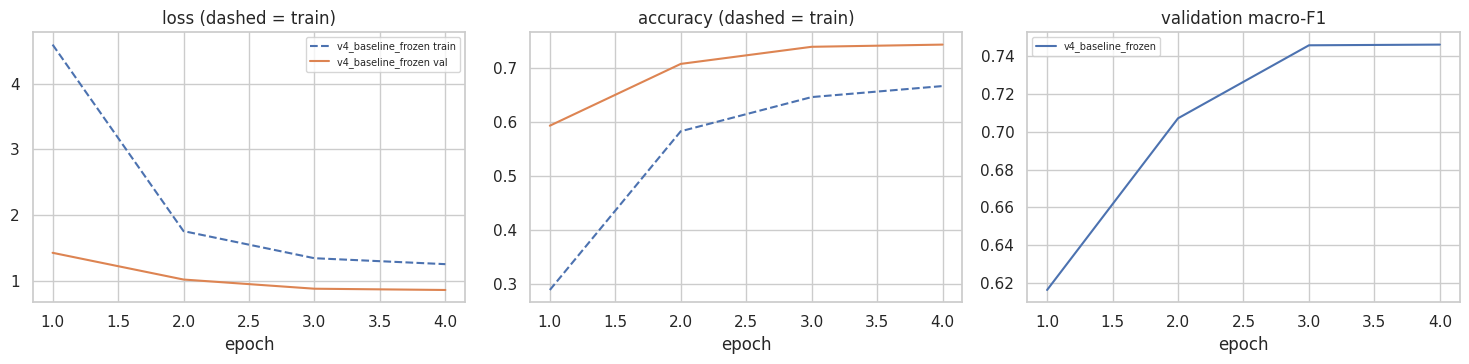

v4_baseline_frozen     train-val acc gap -0.077 | best epoch 4 | OK

Note: train accuracy is measured WITH augmentation, so a small negative gap (val > train) is normal for the strong-aug run.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for tag in [k for k in HISTORY if k.startswith('v4_')]:
    h = HISTORY[tag]
    axes[0].plot(h.epoch, h.train_loss, '--', label=f'{tag} train'); axes[0].plot(h.epoch, h.val_loss, label=f'{tag} val')
    axes[1].plot(h.epoch, h.train_acc, '--'); axes[1].plot(h.epoch, h.val_acc)
    axes[2].plot(h.epoch, h.val_macro_f1, label=tag)
axes[0].set_title('loss (dashed = train)'); axes[1].set_title('accuracy (dashed = train)'); axes[2].set_title('validation macro-F1')
axes[0].legend(fontsize=7); axes[2].legend(fontsize=7)
for a in axes: a.set_xlabel('epoch')
plt.tight_layout(); plt.show()

for tag in [k for k in HISTORY if k.startswith('v4_')]:
    h = HISTORY[tag]; last, best = h.iloc[-1], h.loc[h.val_macro_f1.idxmax()]
    gap = last.train_acc - last.val_acc
    flag = 'possible over-fitting' if gap > 0.05 or last.val_loss > h.val_loss.min() * 1.15 else 'OK'
    print(f'{tag:22s} train-val acc gap {gap:+.3f} | best epoch {int(best.epoch)} | {flag}')
print('\nNote: train accuracy is measured WITH augmentation, so a small negative gap (val > train) is normal for the strong-aug run.')

## 5.4 Error analysis (final model, test set)

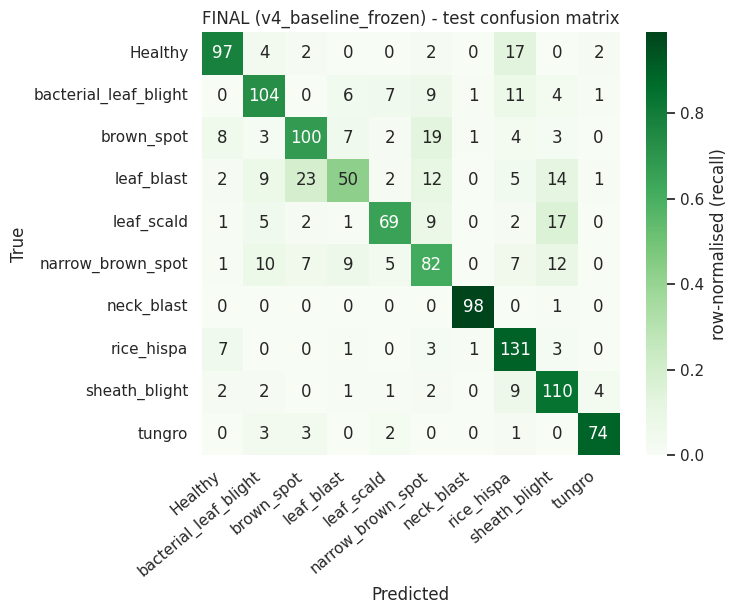

- **Final model (v4_baseline_frozen)** reaches 74.4% accuracy and macro-F1 0.749 on the test set.

- Strongest class: **neck_blast** (F1 0.98); weakest: **leaf_blast** (F1 0.52).

- Most frequent mix-ups: leaf_blast -> brown_spot (23x); brown_spot -> narrow_brown_spot (19x); leaf_scald -> sheath_blight (17x).

- Macro-F1 target of 0.90 is **not yet met**


Errors: 315 / 1230   |   mean confidence when RIGHT 0.906  vs  when WRONG 0.665


,n,errors,error_rate
leaf_blast,118,68,0.576
narrow_brown_spot,133,51,0.383
leaf_scald,106,37,0.349
brown_spot,147,47,0.320
bacterial_leaf_blight,143,39,0.273
Healthy,124,27,0.218
sheath_blight,131,21,0.160
tungro,83,9,0.108
rice_hispa,146,15,0.103
neck_blast,99,1,0.010


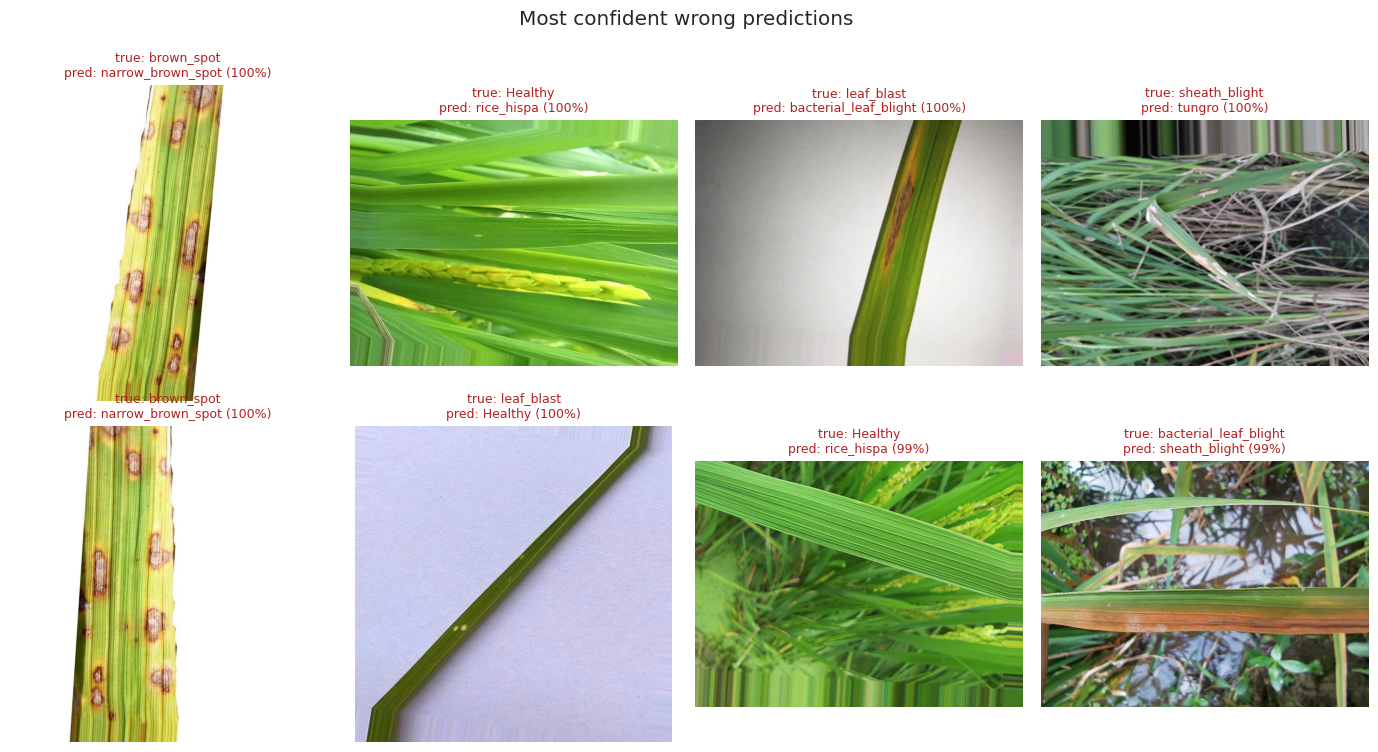

In [ ]:
pt_final = PROBS[FINAL_TAG]['test']; yt = test_df.label.values
cm_final = plot_cm(yt, pt_final, f'FINAL ({FINAL_TAG}) - test confusion matrix')
interpret(yt, pt_final, f'Final model ({FINAL_TAG})')

pred = pt_final.argmax(1); conf = pt_final.max(1); wrong = np.where(pred != yt)[0]
print(f'\nErrors: {len(wrong)} / {len(yt)}   |   mean confidence when RIGHT {conf[pred==yt].mean():.3f}  vs  when WRONG {conf[wrong].mean() if len(wrong) else float("nan"):.3f}')
per_class = pd.DataFrame({'n': np.bincount(yt, minlength=NUM_CLASSES), 'errors': np.bincount(yt[wrong], minlength=NUM_CLASSES)}, index=CLASS_NAMES)
per_class['error_rate'] = (per_class.errors / per_class.n).round(3); display(per_class.sort_values('error_rate', ascending=False))

# ==========================================
#             CHECK MISTAKE
# ==========================================
if len(wrong):
    show = wrong[np.argsort(-conf[wrong])][:8]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5)); axes = axes.ravel()
    for ax, i in zip(axes, show):
        ax.imshow(Image.open(test_df.path[i]).convert('RGB')); ax.axis('off')
        ax.set_title(f'true: {CLASS_NAMES[yt[i]]}\npred: {CLASS_NAMES[pred[i]]} ({conf[i]:.0%})', fontsize=9, color='firebrick')
    for ax in axes[len(show):]: ax.axis('off')
    plt.suptitle('Most confident wrong predictions', y=1.0); plt.tight_layout(); plt.show()
else:
    print('No test errors to display.')

In [ ]:
def ece_score(y, p, bins=10):
    c, pr = p.max(1), p.argmax(1); acc = (pr == y).astype(float); e = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (c > lo) & (c <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - c[m].mean())
    return e

def pick_threshold(y, p, target_acc=0.95, min_coverage=0.5):
    c, pr = p.max(1), p.argmax(1)
    for t in np.arange(0.30, 0.99, 0.01):
        m = c >= t
        if m.mean() >= min_coverage and (pr[m] == y[m]).mean() >= target_acc: return round(float(t), 2), float(m.mean())
    return 0.60, float((c >= 0.60).mean())

yv = val_df.label.values; pv_final = PROBS[FINAL_TAG]['val']
CONF_THRESHOLD, cov = pick_threshold(yv, pv_final)
print(f'ECE (test) = {ece_score(yt, pt_final):.3f}   (0 = perfectly calibrated)')
print(f'Confidence threshold chosen on validation: {CONF_THRESHOLD:.2f}  (keeps {cov:.0%} of val predictions, aiming for >=95% accuracy among them)')
m = pt_final.max(1) >= CONF_THRESHOLD
print(f'On TEST: {m.mean():.0%} of images pass the threshold, accuracy among them {(pred[m]==yt[m]).mean():.3f}; '
      f'the other {(~m).mean():.0%} will be reported as "low confidence - get a second opinion".')

ECE (test) = 0.102   (0 = perfectly calibrated)
Confidence threshold chosen on validation: 0.60  (keeps 84% of val predictions, aiming for >=95% accuracy among them)
On TEST: 83% of images pass the threshold, accuracy among them 0.819; the other 17% will be reported as "low confidence - get a second opinion".


## 5.5 Robustness check - phone photos

In [ ]:
def eval_perturbed(model, extra):
    tfs = [T.Resize((IMG_SIZE, IMG_SIZE))] + ([extra] if extra is not None else []) + [T.ToTensor(), T.Normalize(MEAN, STD)]
    ld = DataLoader(RiceDS(test_df, T.Compose(tfs)), BATCH_SIZE * 2, shuffle=False, num_workers=NUM_WORKERS)
    y, p = predict(model, ld); return f1_score(y, p.argmax(1), average='macro'), accuracy_score(y, p.argmax(1))

PERTURB = {'clean': None, 'darker (x0.6)': T.ColorJitter(brightness=(0.6, 0.6)), 'brighter (x1.5)': T.ColorJitter(brightness=(1.5, 1.5)),
           'blurry': T.GaussianBlur(9, sigma=3), 'low-res (64px, upscaled)': T.Compose([T.Resize((64, 64)), T.Resize((IMG_SIZE, IMG_SIZE))])}
rob = pd.DataFrame([(k, *eval_perturbed(FINAL_MODEL, v)) for k, v in PERTURB.items()], columns=['condition', 'macro_F1', 'accuracy']).round(3)
rob['drop_vs_clean'] = (rob.macro_F1 - rob.macro_F1.iloc[0]).round(3); display(rob)
rob.to_csv(OUT_DIR / 'week5_robustness.csv', index=False)

,condition,macro_F1,accuracy,drop_vs_clean
0,clean,0.749,0.744,0.000
1,darker (x0.6),0.733,0.728,-0.016
2,brighter (x1.5),0.705,0.698,-0.044
3,blurry,0.386,0.409,-0.363
4,"low-res (64px, upscaled)",0.407,0.421,-0.342


## 5.6 Limitations, risks and possible bias
| Risk | Why it matters | Mitigation in this project |
|---|---|---|
| **Dataset bias** | Photos in public datasets are often taken on plain backgrounds, one camera, one region/variety. Field photos (soil, water, shadows, several leaves) look different → real accuracy will be **lower** than the test score | Robustness check (§5.5); tell users to photograph **one leaf, good light, plain background** |
| **Data leakage** | `Augmented/` copies of the same photo in train *and* test inflate scores | Split on `Original/` only + hash-based duplicate checks |
| **Look-alike diseases** | Brown spot, narrow brown leaf spot and leaf blast can look similar early on | Show top-3 + low-confidence warning + "ask a technician" advice |
| **Class imbalance** | A rare class can be neglected | Macro-F1, per-class recall, optional class weights |
| **Rice Hispa is an insect, not a disease** | Advice differs (scouting/insecticide vs. fungicide) | Knowledge base has a separate entry that says so |
| **No "not a rice leaf" class** | A photo of something else still gets one of the 8 labels | Confidence threshold (partial protection only) |
| **Single-leaf photo ≠ field severity** | One leaf cannot tell whether 2 % or 60 % of the field is affected | Advice says to scout several spots before spending money |
| **Treatment advice is generic** | Chemicals/registrations vary by country and by crop stage | Only classes of actions are suggested, always "follow the local label / technician" |
| **Small test set → noisy estimates** | A few images move the score by a point or two | Report confidence intervals if you need to claim a difference between two models |
| **Possible mislabels** | Public datasets contain a few wrong labels | Look at the most confident "errors" (§5.4): some may be label mistakes |

---
# WEEK 6 · Machine Learning Documentation

| Deliverable | Where |
|---|---|
| Draft the methods, model, evaluation and discussion sections | §6.3 (auto-filled with *your* numbers → `outputs/CSST102_report_draft.md`) |
| Organise and explain key parts of the Colab notebook | §6.1 |
| Add references, data source and model limitations | §6.3 |
| Restart and run all notebook cells to test reproducibility | §6.2 |

## 6.1 Notebook map
| Part | Cells do… | Key objects |
|---|---|---|
| Setup / CONFIG | imports, seeds, paths | `CONFIG`, `set_seed`, `DEVICE` |
| Week 2 | scan folders, check corrupt/duplicate images, clean, encode | `df_clean`, `CLASS_NAMES` |
| Week 3 | split, transforms, `fit()`, baseline | `train_df/val_df/test_df`, `make_loaders`, `fit` |
| Week 4 | metrics, interpretation, 2nd model | `metrics_summary`, `RESULTS` |
| Week 5 | experiments, selection, errors, calibration, robustness | `FINAL_TAG`, `FINAL_MODEL`, `CONF_THRESHOLD` |
| Week 7 | advice knowledge-base, `diagnose()`, demo | `KB`, `diagnose` |

## 6.2 How to re-run (reproducibility test)
1. `Runtime ▸ Change runtime type ▸ T4 GPU`
2. Edit only the **CONFIG** cell (dataset location / `DATASET_SOURCE_NOTE`).
3. `Runtime ▸ Restart session and run all`.  Seeds are fixed (`SEED = 42`), so metrics should match to within a small GPU-nondeterminism tolerance.
4. Optional quick test first: `QUICK_RUN = True`.

In [ ]:
# ==========================================
#             6.2 REPRODUCIBILITY
# ==========================================
import subprocess, platform
freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout.splitlines()
keep = [l for l in freeze if l.split('==')[0].lower() in {'torch', 'torchvision', 'timm', 'scikit-learn', 'numpy', 'pandas', 'pillow', 'matplotlib', 'seaborn'}]
(OUT_DIR / 'requirements_used.txt').write_text('\n'.join(keep))
config_used = dict(QUICK_RUN=QUICK_RUN, MODEL_NAME=MODEL_NAME, SECOND_MODEL_NAME=SECOND_MODEL_NAME, IMG_SIZE=IMG_SIZE,
                   BATCH_SIZE=BATCH_SIZE, EPOCHS_BASELINE=EPOCHS_BASELINE, EPOCHS_FINETUNE=EPOCHS_FINETUNE, SEED=SEED,
                   FINAL_TAG=FINAL_TAG, CONF_THRESHOLD=CONF_THRESHOLD, python=platform.python_version(), classes=CLASS_NAMES)
(OUT_DIR / 'config_used.json').write_text(json.dumps(config_used, indent=2))

_, p_chk = predict(FINAL_MODEL, make_loaders('basic')[2])
chk = metrics_summary(test_df.label.values, p_chk)
assert abs(chk['macro_f1'] - RESULTS[FINAL_TAG]['test']['macro_f1']) < 0.01, 'checkpoint does not reproduce recorded metrics!'
print('reloaded checkpoint reproduces test macro-F1:', round(chk['macro_f1'], 4)); print(*keep, sep='\n')

reloaded checkpoint reproduces test macro-F1: 0.7485
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
pillow==11.3.0
scikit-learn==1.6.1
seaborn==0.13.2
timm==1.0.31


## 6.3 Report draft (auto-filled from this run — copy into Word / your template)

In [ ]:
def build_report():
    r0, rf = RESULTS['v4_baseline_frozen'], RESULTS[FINAL_TAG]
    t, b = rf['test'], r0['test']
    pc = classification_report(test_df.label.values, PROBS[FINAL_TAG]['test'].argmax(1), labels=list(range(NUM_CLASSES)),
                               target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    pc_md = '\n'.join(f'| {c} | {pc[c]["precision"]:.3f} | {pc[c]["recall"]:.3f} | {pc[c]["f1-score"]:.3f} | {int(pc[c]["support"])} |' for c in CLASS_NAMES)
    runs_md = '\n'.join(f'| {k} | {r["setup"]} | {r["val"]["macro_f1"]:.3f} | {r["test"]["accuracy"]:.3f} | {r["test"]["macro_f1"]:.3f} | {r["params_M"]:.1f} | {r["latency_ms"]:.1f} |' for k, r in RESULTS.items())
    return f"""# Rice Leaf Disease Classification with MobileNetV4
*Machine Learning project report*

## 1. Introduction
Rice diseases and pests reduce yield and are difficult to distinguish visually. This project builds an image classifier that assigns a photo of a rice leaf to one of {NUM_CLASSES} classes ({', '.join(CLASS_NAMES)}) and attaches a simple urgency level and management advice to the prediction.

## 2. Data
- Source: {DATASET_SOURCE_NOTE}
- Structure: `Original/` and `Augmented/` folders with one sub-folder per class. Only `Original/` was used for splitting and evaluation to prevent leakage from augmented copies.
- After removing unreadable files, label conflicts and exact duplicates: **{len(df_clean)} images** ({len(train_df)} train / {len(val_df)} validation / {len(test_df)} test, stratified, seed {SEED}).
- Largest/smallest class ratio: {IMBALANCE_RATIO:.2f}.

## 3. Methods
**Preprocessing.** Images converted to RGB, resized to {IMG_SIZE}x{IMG_SIZE}, normalised with ImageNet mean/std. Training augmentation: random flips (baseline) and, in the strong setting, random resized crop, rotation, small brightness/contrast jitter and random erasing.

**Model.** MobileNetV4-Conv-Medium (`{MODEL_NAME}`, {rf['params_M']:.1f} M parameters) pretrained on ImageNet-1k, with a new {NUM_CLASSES}-way classification head. Baseline: backbone frozen, head trained. Final: `{FINAL_TAG}` ({rf['setup']}). Optimiser AdamW with one-cycle learning-rate schedule, mixed precision, early stopping on validation macro-F1. A second model, MobileNetV3-Large (`{SECOND_MODEL_NAME}`), was trained with the baseline recipe for comparison.

**Evaluation.** Accuracy, macro-F1, per-class precision/recall, confusion matrix, top-3 accuracy, log-loss and one-vs-rest ROC-AUC on the held-out test set. The final model was selected using validation macro-F1 only.

## 4. Results
| Run | Setup | Val macro-F1 | Test acc | Test macro-F1 | Params (M) | Latency (ms/img) |
|---|---|---|---|---|---|---|
{runs_md}

Final model `{FINAL_TAG}`: accuracy **{t['accuracy']:.3f}**, macro-F1 **{t['macro_f1']:.3f}**, top-3 accuracy {t['top3_acc']:.3f}, ROC-AUC {t['roc_auc_ovr']:.3f}, log-loss {t['log_loss']:.3f}. Change vs. frozen baseline: macro-F1 {t['macro_f1']-b['macro_f1']:+.3f}.

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
{pc_md}

## 5. Discussion
The macro-F1 objective of 0.90 was {'met' if t['macro_f1'] >= 0.90 else 'not met'} ({t['macro_f1']:.3f}). Fine-tuning changed macro-F1 by {t['macro_f1']-b['macro_f1']:+.3f} relative to the frozen baseline. The most frequent confusions were: {'; '.join(f'{a} -> {c} ({n}x)' for a, c, n in top_confusions(cm_final, 3)) or 'none'}. Under image perturbations (darker/brighter/blurry/low-resolution) the worst macro-F1 was {rob.macro_F1.min():.3f} versus {rob.macro_F1.iloc[0]:.3f} on clean images. A confidence threshold of {CONF_THRESHOLD:.2f}, chosen on the validation set, is used to flag uncertain predictions.

## 6. Limitations and risks
Public-dataset photos are cleaner than field photos, so real-world accuracy will likely be lower; look-alike diseases (brown spot / narrow brown leaf spot / leaf blast) are the main source of error; there is no "not a rice leaf" class; a single leaf cannot show field-level severity; and treatment advice is general and must be confirmed with a local agricultural technician and local pesticide regulations.

## 7. Conclusion
A MobileNetV4 transfer-learning model achieves test accuracy {t['accuracy']:.1%} on 8 rice-leaf classes with a small, fast network ({rf['params_M']:.1f} M parameters, ~{rf['latency_ms']:.0f} ms per image on this runtime), which makes it a suitable base for a mobile or web app. Future work: field-collected photos, severity estimation, a 'not rice' class, and on-device export (ONNX / TFLite).

## References
1. Qin, D., Leichner, C., Delakis, M., et al. (2024). *MobileNetV4 - Universal Models for the Mobile Ecosystem.* ECCV 2024. arXiv:2404.10518.
2. Wightman, R. (2019). *PyTorch Image Models (timm).* https://github.com/huggingface/pytorch-image-models  doi:10.5281/zenodo.4414861
3. Paszke, A., et al. (2019). *PyTorch: An Imperative Style, High-Performance Deep Learning Library.* NeurIPS 32.
4. Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12, 2825-2830.
5. Howard, A., et al. (2019). *Searching for MobileNetV3.* ICCV 2019.
6. Loshchilov, I., & Hutter, F. (2019). *Decoupled Weight Decay Regularization.* ICLR 2019.
7. Deng, J., et al. (2009). *ImageNet: A large-scale hierarchical image database.* CVPR 2009.
8. IRRI Rice Knowledge Bank (disease and pest management fact sheets). http://www.knowledgebank.irri.org
9. Dataset: {DATASET_SOURCE_NOTE}
"""

REPORT_MD = build_report()
(OUT_DIR / 'CSST102_report_draft.md').write_text(REPORT_MD, encoding='utf-8')
display(Markdown(REPORT_MD))
print('saved ->', OUT_DIR / 'CSST102_report_draft.md')

# Rice Leaf Disease Classification with MobileNetV4
*Machine Learning project report*

## 1. Introduction
Rice diseases and pests reduce yield and are difficult to distinguish visually. This project builds an image classifier that assigns a photo of a rice leaf to one of 10 classes (Healthy, bacterial_leaf_blight, brown_spot, leaf_blast, leaf_scald, narrow_brown_spot, neck_blast, rice_hispa, sheath_blight, tungro) and attaches a simple urgency level and management advice to the prediction.

## 2. Data
- Source: 
- Structure: `Original/` and `Augmented/` folders with one sub-folder per class. Only `Original/` was used for splitting and evaluation to prevent leakage from augmented copies.
- After removing unreadable files, label conflicts and exact duplicates: **8200 images** (5740 train / 1230 validation / 1230 test, stratified, seed 42).
- Largest/smallest class ratio: 1.76.

## 3. Methods
**Preprocessing.** Images converted to RGB, resized to 256x256, normalised with ImageNet mean/std. Training augmentation: random flips (baseline) and, in the strong setting, random resized crop, rotation, small brightness/contrast jitter and random erasing.

**Model.** MobileNetV4-Conv-Medium (`mobilenetv4_conv_medium.e500_r256_in1k`, 8.4 M parameters) pretrained on ImageNet-1k, with a new 10-way classification head. Baseline: backbone frozen, head trained. Final: `v4_baseline_frozen` (frozen backbone, head only). Optimiser AdamW with one-cycle learning-rate schedule, mixed precision, early stopping on validation macro-F1. A second model, MobileNetV3-Large (`mobilenetv3_large_100.ra_in1k`), was trained with the baseline recipe for comparison.

**Evaluation.** Accuracy, macro-F1, per-class precision/recall, confusion matrix, top-3 accuracy, log-loss and one-vs-rest ROC-AUC on the held-out test set. The final model was selected using validation macro-F1 only.

## 4. Results
| Run | Setup | Val macro-F1 | Test acc | Test macro-F1 | Params (M) | Latency (ms/img) |
|---|---|---|---|---|---|---|
| v4_baseline_frozen | frozen backbone, head only | 0.746 | 0.744 | 0.749 | 8.4 | 57.4 |
| v3_frozen | frozen backbone, head only | 0.826 | 0.809 | 0.812 | 4.2 | 30.7 |

Final model `v4_baseline_frozen`: accuracy **0.744**, macro-F1 **0.749**, top-3 accuracy 0.930, ROC-AUC 0.963, log-loss 0.831. Change vs. frozen baseline: macro-F1 +0.000.

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Healthy | 0.822 | 0.782 | 0.802 | 124 |
| bacterial_leaf_blight | 0.743 | 0.727 | 0.735 | 143 |
| brown_spot | 0.730 | 0.680 | 0.704 | 147 |
| leaf_blast | 0.667 | 0.424 | 0.518 | 118 |
| leaf_scald | 0.784 | 0.651 | 0.711 | 106 |
| narrow_brown_spot | 0.594 | 0.617 | 0.605 | 133 |
| neck_blast | 0.970 | 0.990 | 0.980 | 99 |
| rice_hispa | 0.701 | 0.897 | 0.787 | 146 |
| sheath_blight | 0.671 | 0.840 | 0.746 | 131 |
| tungro | 0.902 | 0.892 | 0.897 | 83 |

## 5. Discussion
The macro-F1 objective of 0.90 was not met (0.749). Fine-tuning changed macro-F1 by +0.000 relative to the frozen baseline. The most frequent confusions were: leaf_blast -> brown_spot (23x); brown_spot -> narrow_brown_spot (19x); leaf_scald -> sheath_blight (17x). Under image perturbations (darker/brighter/blurry/low-resolution) the worst macro-F1 was 0.386 versus 0.749 on clean images. A confidence threshold of 0.60, chosen on the validation set, is used to flag uncertain predictions.

## 6. Limitations and risks
Public-dataset photos are cleaner than field photos, so real-world accuracy will likely be lower; look-alike diseases (brown spot / narrow brown leaf spot / leaf blast) are the main source of error; there is no "not a rice leaf" class; a single leaf cannot show field-level severity; and treatment advice is general and must be confirmed with a local agricultural technician and local pesticide regulations.

## 7. Conclusion
A MobileNetV4 transfer-learning model achieves test accuracy 74.4% on 8 rice-leaf classes with a small, fast network (8.4 M parameters, ~57 ms per image on this runtime), which makes it a suitable base for a mobile or web app. Future work: field-collected photos, severity estimation, a 'not rice' class, and on-device export (ONNX / TFLite).

## References
1. Qin, D., Leichner, C., Delakis, M., et al. (2024). *MobileNetV4 - Universal Models for the Mobile Ecosystem.* ECCV 2024. arXiv:2404.10518.
2. Wightman, R. (2019). *PyTorch Image Models (timm).* https://github.com/huggingface/pytorch-image-models  doi:10.5281/zenodo.4414861
3. Paszke, A., et al. (2019). *PyTorch: An Imperative Style, High-Performance Deep Learning Library.* NeurIPS 32.
4. Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12, 2825-2830.
5. Howard, A., et al. (2019). *Searching for MobileNetV3.* ICCV 2019.
6. Loshchilov, I., & Hutter, F. (2019). *Decoupled Weight Decay Regularization.* ICLR 2019.
7. Deng, J., et al. (2009). *ImageNet: A large-scale hierarchical image database.* CVPR 2009.
8. IRRI Rice Knowledge Bank (disease and pest management fact sheets). http://www.knowledgebank.irri.org
9. Dataset: 


saved -> /content/drive/MyDrive/Rice_Leaf_Disease_Project/outputs/CSST102_report_draft.md


---
# WEEK 7 · Final Machine Learning Project Submission



In [ ]:
FINAL_MODEL = load_checkpoint(FINAL_TAG)
_, _, test_loader_final = make_loaders('basic')
y_f, p_f = predict(FINAL_MODEL, test_loader_final)
FINAL_METRICS = metrics_summary(y_f, p_f)
display(pd.Series(FINAL_METRICS).round(4).to_frame('FINAL TEST METRICS').T)
print(classification_report(y_f, p_f.argmax(1), labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES, digits=3, zero_division=0))
_, pth = save_predictions(test_df, p_f, 'FINAL_predictions_test')
print('final predictions saved ->', pth)
assert abs(FINAL_METRICS['macro_f1'] - RESULTS[FINAL_TAG]['test']['macro_f1']) < 0.01, 'reported metrics != notebook outputs'
print('reported metrics match the notebook outputs')

,accuracy,balanced_acc,macro_precision,macro_recall,macro_f1,weighted_f1,top3_acc,log_loss,roc_auc_ovr
FINAL TEST METRICS,0.7439,0.7499,0.7584,0.7499,0.7485,0.7391,0.9301,0.8307,0.9633


                       precision    recall  f1-score   support

              Healthy      0.822     0.782     0.802       124
bacterial_leaf_blight      0.743     0.727     0.735       143
           brown_spot      0.730     0.680     0.704       147
           leaf_blast      0.667     0.424     0.518       118
           leaf_scald      0.784     0.651     0.711       106
    narrow_brown_spot      0.594     0.617     0.605       133
           neck_blast      0.970     0.990     0.980        99
           rice_hispa      0.701     0.897     0.787       146
        sheath_blight      0.671     0.840     0.746       131
               tungro      0.902     0.892     0.897        83

             accuracy                          0.744      1230
            macro avg      0.758     0.750     0.749      1230
         weighted avg      0.746     0.744     0.739      1230

final predictions saved -> /content/drive/MyDrive/Rice_Leaf_Disease_Project/outputs/FINAL_predictions_test.csv
repo

## 7.2 The advice layer — class → type → urgency → simple treatment
This is a **rule-based knowledge base** (not learned). It is deliberately simple and generic; it is based on widely published rice-extension guidance (e.g. IRRI Rice Knowledge Bank). Urgency scale: 🟢 none · 🟡 low (monitor) · 🟠 moderate (act within about a week) · 🔴 high (act within 1–3 days).

In [44]:
KB = {
 'healthy': dict(
    type='No disease detected', urgency=0, act_within='no action needed',
    what='The leaf looks healthy: uniform green, no lesions, streaks or spots.',
    actions=['Keep scouting the field about once a week - one healthy leaf does not mean the whole field is healthy.',
             'Keep balanced fertiliser (avoid too much nitrogen) and good water management.',
             'Use clean seed and remove weeds around the field to keep it that way.']),
 'bacterial leaf blight': dict(
    type='Bacterial disease (Xanthomonas oryzae pv. oryzae)', urgency=3, act_within='1-3 days',
    what='Yellow to white, water-soaked stripes with wavy edges that start at leaf tips/edges and run down the leaf; young plants may wilt ("kresek"). Spreads through irrigation water, rain splash and wounds, and is worse with too much nitrogen.',
    actions=['There is no reliable cure once plants are infected, so the goal is to STOP THE SPREAD.',
             'Stop or reduce nitrogen top-dressing now.',
             'Do not let water flow from the infected plot into healthy plots; avoid walking/working in the field when plants are wet.',
             'Remove and destroy badly infected plants and nearby weeds; do not clip seedlings from infected nurseries.',
             'Copper-based sprays only slow the spread a little - ask your agricultural technician before spending on chemicals.',
             'Next season: resistant varieties, clean/certified seed, split nitrogen, destroy stubble.']),
 'brown spot': dict(
    type='Fungal disease (Bipolaris oryzae)', urgency=2, act_within='within about a week',
    what='Oval brown spots with a grey/tan centre, often with a yellow halo. It is strongly linked to poor or nutrient-deficient soil and water stress, and can be carried on seed.',
    actions=['Fix the underlying cause: apply balanced fertiliser (check potassium, nitrogen and silicon status - a soil test helps).',
             'Avoid drought stress; keep water supply steady.',
             'If many upper leaves are spotted, a locally registered fungicide (e.g. triazole or strobilurin group) can be used - follow the label.',
             'Remove infected straw/debris; next season use treated, clean seed and tolerant varieties.']),
 'leaf blast': dict(
    type='Fungal disease (Magnaporthe oryzae)', urgency=3, act_within='1-3 days (before booting/heading if possible)',
    what='Diamond- or spindle-shaped lesions with a grey/white centre and brown border. Leaf blast can progress to neck blast on the panicle, which causes the largest yield loss. Favoured by heavy dew, cool humid nights and excess nitrogen.',
    actions=['Treat early: apply a locally registered anti-blast fungicide (e.g. tricyclazole, or a strobilurin/triazole product) strictly following the label and local advice.',
             'Hold back extra nitrogen; split nitrogen into smaller doses.',
             'Keep the field well supplied with water (drought stress makes blast worse) and avoid very dense planting.',
             'Re-check the field after a few days, especially around booting/heading, when neck blast risk starts.',
             'Next season: resistant varieties, clean seed, avoid late planting in humid weather.']),
 'leaf scald': dict(
    type='Fungal disease (Monographella albescens)', urgency=1, act_within='monitor; act within 1-2 weeks if spreading',
    what='Large lesions that begin at leaf tips or edges, with a banded (zonate) tan-and-brown pattern that looks "scalded". Usually a minor disease, more common with high nitrogen and humid, late-season weather.',
    actions=['Usually no spraying is needed - monitor whether it spreads to upper leaves.',
             'Reduce excess nitrogen and keep the field clean of weeds and crop residue.',
             'Use clean seed next season; ask a technician about fungicide only if infection is heavy near heading.']),
 'narrow brown spot': dict(
    type='Fungal disease (Cercospora janseana)', urgency=1, act_within='monitor; act within 1-2 weeks if spreading',
    what='Short, narrow, reddish-brown lines running along the leaf veins. Common late in the season and linked to potassium deficiency; usually a minor disease.',
    actions=['Usually no spraying is needed.',
             'Check the nutrition: balanced fertiliser, especially enough potassium.',
             'Use tolerant varieties next season; consider a fungicide only if the flag leaf is heavily affected before heading (ask a technician).']),
 'rice hispa': dict(
    type='INSECT pest (rice hispa beetle, Dicladispa armigera) - not a disease', urgency=2, act_within='2-3 days if many beetles are found',
    what='Adults scrape the leaf surface, leaving white/translucent parallel streaks; grubs mine inside the leaf. Damage looks like a disease but the cause is a small spiny blue-black beetle. Worst in young crops and after heavy nitrogen use.',
    actions=['Scout: check several hills in different spots for beetles/grubs before deciding - spray only if the infestation is clearly widespread.',
             'In seedbeds/young crop, clip and destroy damaged leaf tips; remove grassy weeds on bunds that host the beetle.',
             'Avoid excess nitrogen and over-dense planting; protect natural enemies by not spraying unnecessarily.',
             'If infestation is heavy, use an insecticide locally recommended for rice hispa - follow label and safety rules. (Fungicide will not help.)']),
 'sheath blight': dict(
    type='Fungal disease (Rhizoctonia solani)', urgency=3, act_within='1-3 days if lesions are climbing up the plant',
    what='Oval or irregular greenish-grey lesions with brown borders on the leaf sheath near the water line; they merge and climb upward, damaging the flag leaf. Worst in dense crops, high nitrogen, warm humid weather.',
    actions=['Act while lesions are still low on the plant: apply a locally registered fungicide (e.g. validamycin, or a triazole/strobilurin product) following the label.',
             'Reduce nitrogen; open up the canopy where possible and let the water level drop for short periods.',
             'Remove weeds and floating debris/sclerotia from the field edges.',
             'Next season: wider spacing, split nitrogen, manage residue, choose less susceptible varieties.']),
 'neck blast': dict(
    type='Bacterial disease (Xanthomonas oryzae pv. oryzae)', urgency=3, act_within='1-3 days',
    what='Yellow to white, water-soaked stripes with wavy edges that start at leaf tips/edges and run down the leaf; young plants may wilt ("kresek"). Spreads through irrigation water, rain splash and wounds, and is worse with too much nitrogen.',
    actions=['There is no reliable cure once plants are infected, so the goal is to STOP THE SPREAD.',
             'Stop or reduce nitrogen top-dressing now.',
             'Do not let water flow from the infected plot into healthy plots; avoid walking/working in the field when plants are wet.',
             'Remove and destroy badly infected plants and nearby weeds; do not clip seedlings from infected nurseries.',
             'Copper-based sprays only slow the spread a little - ask your agricultural technician before spending on chemicals.',
             'Next season: resistant varieties, clean/certified seed, split nitrogen, destroy stubble.']),
 'tungro': dict(
    type='Bacterial disease (Xanthomonas oryzae pv. oryzae)', urgency=3, act_within='1-3 days',
    what='Yellow to white, water-soaked stripes with wavy edges that start at leaf tips/edges and run down the leaf; young plants may wilt ("kresek"). Spreads through irrigation water, rain splash and wounds, and is worse with too much nitrogen.',
    actions=['There is no reliable cure once plants are infected, so the goal is to STOP THE SPREAD.',
             'Stop or reduce nitrogen top-dressing now.',
             'Do not let water flow from the infected plot into healthy plots; avoid walking/working in the field when plants are wet.',
             'Remove and destroy badly infected plants and nearby weeds; do not clip seedlings from infected nurseries.',
             'Copper-based sprays only slow the spread a little - ask your agricultural technician before spending on chemicals.',
             'Next season: resistant varieties, clean/certified seed, split nitrogen, destroy stubble.']),
}
URG = {0: ('🟢', 'NONE'), 1: ('🟡', 'LOW'), 2: ('🟠', 'MODERATE'), 3: ('🔴', 'HIGH - URGENT')}
DISCLAIMER = ('This is an AI first-aid suggestion from a leaf photo, not a diagnosis. Check several plants/spots in the field and '
              'confirm with a local agricultural technician before spraying. Follow the label and local regulations for any product.')

def kb_lookup(name):
    key = name.strip().lower().replace('_', ' ')
    return KB.get(key, dict(type='Unknown', urgency=2, act_within='ask a technician', what='No advice entry for this class.', actions=[]))

missing = [c for c in CLASS_NAMES if c.strip().lower().replace('_', ' ') not in KB]
assert not missing, f'Add these classes to KB: {missing}'
print('knowledge base covers all', len(CLASS_NAMES), 'classes')

knowledge base covers all 10 classes


## 7.3 `diagnose()` — photo in, report out

In [45]:
@torch.no_grad()
def diagnose(img, model=None, topk=3, conf_threshold=None, show=True):
    model = model or FINAL_MODEL; thr = conf_threshold or CONF_THRESHOLD
    if isinstance(img, (str, Path)): img = Image.open(img)
    img = img.convert('RGB')
    model.eval(); p = F.softmax(model(EVAL_TF(img).unsqueeze(0).to(DEVICE)).float(), 1)[0].cpu().numpy()
    order = p.argsort()[::-1][:topk]
    best, conf = CLASS_NAMES[order[0]], float(p[order[0]]); info = kb_lookup(best)
    confident = conf >= thr
    icon, ulabel = URG[info['urgency']]
    L = ['🌾 RICE LEAF REPORT', '=' * 60]
    if confident:
        L += [f'Prediction : {best}   (confidence {conf:.1%})', f'Type       : {info["type"]}']
        L += [f'Urgency    : {icon} {ulabel}  - act {info["act_within"]}']
    else:
        L += [f'⚠️  LOW CONFIDENCE ({conf:.1%} < {thr:.0%}) - best guess only: {best}',
              'Please retake the photo (ONE leaf, daylight, plain background, in focus) and/or ask a technician.',
              f'If the guess is right: {icon} {ulabel} - act {info["act_within"]}']
    L += ['', 'Top guesses: ' + ' | '.join(f'{CLASS_NAMES[i]} {p[i]:.0%}' for i in order), '', 'What it is:', '  ' + info['what']]
    if info['actions']:
        L += ['', 'What you can do:'] + [f'  {k}. {a}' for k, a in enumerate(info['actions'], 1)]
    L += ['', DISCLAIMER]
    text = '\n'.join(L)
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1, 1.3]})
        ax[0].imshow(img); ax[0].axis('off'); ax[0].set_title(f'{best}  {conf:.0%}', color='tab:green' if confident else 'tab:orange')
        ax[1].barh([CLASS_NAMES[i] for i in order][::-1], [p[i] for i in order][::-1], color='#4c9a6a'); ax[1].set_xlim(0, 1)
        ax[1].set_title('top predictions'); plt.tight_layout(); plt.show(); print(text)
    return dict(prediction=best, confidence=conf, confident=confident, urgency=ulabel, act_within=info['act_within'],
                top=[(CLASS_NAMES[i], float(p[i])) for i in order], report_text=text)
print('diagnose() ready')

diagnose() ready


## 7.4 Demo A — a few test-set leaves


######## true label: bacterial_leaf_blight


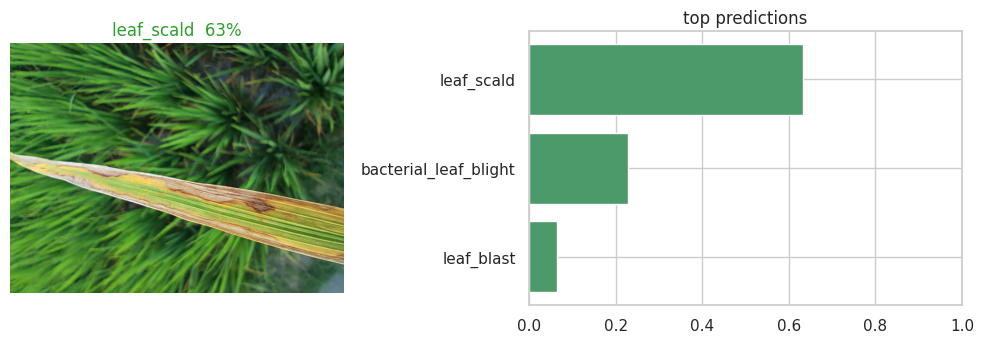

🌾 RICE LEAF REPORT
Prediction : leaf_scald   (confidence 63.3%)
Type       : Fungal disease (Monographella albescens)
Urgency    : 🟡 LOW  - act monitor; act within 1-2 weeks if spreading

Top guesses: leaf_scald 63% | bacterial_leaf_blight 23% | leaf_blast 7%

What it is:
  Large lesions that begin at leaf tips or edges, with a banded (zonate) tan-and-brown pattern that looks "scalded". Usually a minor disease, more common with high nitrogen and humid, late-season weather.

What you can do:
  1. Usually no spraying is needed - monitor whether it spreads to upper leaves.
  2. Reduce excess nitrogen and keep the field clean of weeds and crop residue.
  3. Use clean seed next season; ask a technician about fungicide only if infection is heavy near heading.

This is an AI first-aid suggestion from a leaf photo, not a diagnosis. Check several plants/spots in the field and confirm with a local agricultural technician before spraying. Follow the label and local regulations for any product.

#

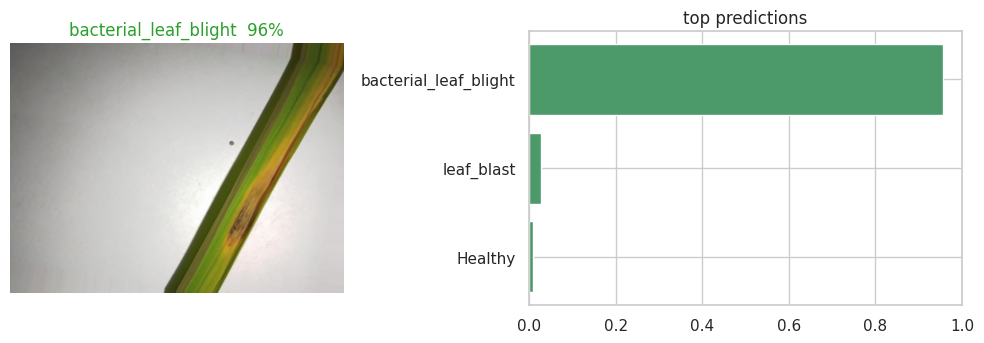

🌾 RICE LEAF REPORT
Prediction : bacterial_leaf_blight   (confidence 95.6%)
Type       : Bacterial disease (Xanthomonas oryzae pv. oryzae)
Urgency    : 🔴 HIGH - URGENT  - act 1-3 days

Top guesses: bacterial_leaf_blight 96% | leaf_blast 3% | Healthy 1%

What it is:
  Yellow to white, water-soaked stripes with wavy edges that start at leaf tips/edges and run down the leaf; young plants may wilt ("kresek"). Spreads through irrigation water, rain splash and wounds, and is worse with too much nitrogen.

What you can do:
  1. There is no reliable cure once plants are infected, so the goal is to STOP THE SPREAD.
  2. Stop or reduce nitrogen top-dressing now.
  3. Do not let water flow from the infected plot into healthy plots; avoid walking/working in the field when plants are wet.
  4. Remove and destroy badly infected plants and nearby weeds; do not clip seedlings from infected nurseries.
  5. Copper-based sprays only slow the spread a little - ask your agricultural technician before spendi

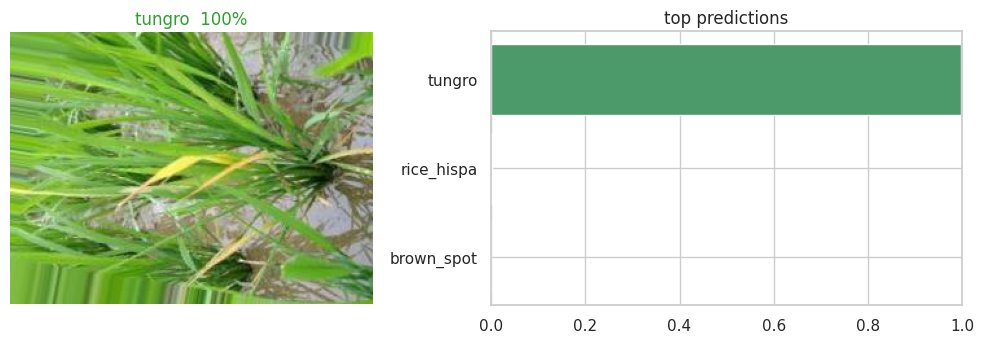

🌾 RICE LEAF REPORT
Prediction : tungro   (confidence 99.8%)
Type       : Bacterial disease (Xanthomonas oryzae pv. oryzae)
Urgency    : 🔴 HIGH - URGENT  - act 1-3 days

Top guesses: tungro 100% | rice_hispa 0% | brown_spot 0%

What it is:
  Yellow to white, water-soaked stripes with wavy edges that start at leaf tips/edges and run down the leaf; young plants may wilt ("kresek"). Spreads through irrigation water, rain splash and wounds, and is worse with too much nitrogen.

What you can do:
  1. There is no reliable cure once plants are infected, so the goal is to STOP THE SPREAD.
  2. Stop or reduce nitrogen top-dressing now.
  3. Do not let water flow from the infected plot into healthy plots; avoid walking/working in the field when plants are wet.
  4. Remove and destroy badly infected plants and nearby weeds; do not clip seedlings from infected nurseries.
  5. Copper-based sprays only slow the spread a little - ask your agricultural technician before spending on chemicals.
  6. Next

In [46]:
demo = test_df.sample(min(3, len(test_df)), random_state=7)
for _, row in demo.iterrows():
    print(f'\n######## true label: {row.class_name}')
    diagnose(row.path)

## 7.5 Demo B — upload **your own** rice-leaf photo

Saving augmented_image_8.jpg to augmented_image_8.jpg

######## augmented_image_8.jpg


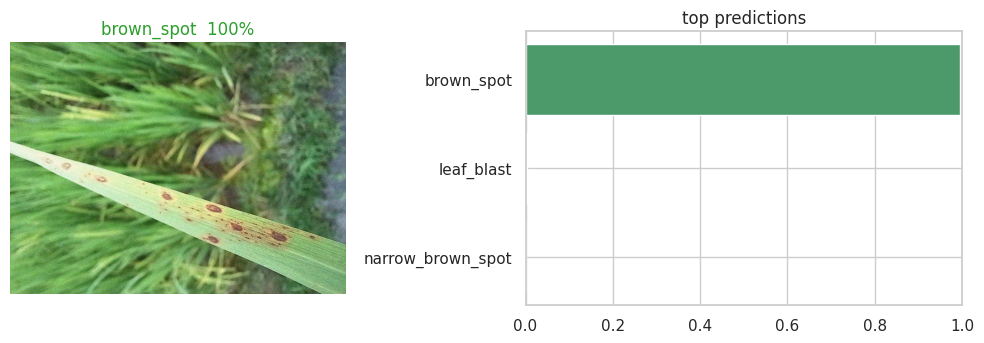

🌾 RICE LEAF REPORT
Prediction : brown_spot   (confidence 99.5%)
Type       : Fungal disease (Bipolaris oryzae)
Urgency    : 🟠 MODERATE  - act within about a week

Top guesses: brown_spot 100% | leaf_blast 0% | narrow_brown_spot 0%

What it is:
  Oval brown spots with a grey/tan centre, often with a yellow halo. It is strongly linked to poor or nutrient-deficient soil and water stress, and can be carried on seed.

What you can do:
  1. Fix the underlying cause: apply balanced fertiliser (check potassium, nitrogen and silicon status - a soil test helps).
  2. Avoid drought stress; keep water supply steady.
  3. If many upper leaves are spotted, a locally registered fungicide (e.g. triazole or strobilurin group) can be used - follow the label.
  4. Remove infected straw/debris; next season use treated, clean seed and tolerant varieties.

This is an AI first-aid suggestion from a leaf photo, not a diagnosis. Check several plants/spots in the field and confirm with a local agricultural tech

In [47]:
# run this cell, click "Choose files", pick a photo of a rice leaf (taken with your phone is perfect)
try:
    from google.colab import files
    up = files.upload()
    for fn in up: print(f'\n######## {fn}'); diagnose(fn)
except ImportError:
    print('Not running in Colab - call diagnose("path/to/photo.jpg") instead.')

In [ ]:
# optional: clickable web demo (set RUN_GRADIO = True in CONFIG).  Gives a public link you can open on your phone.
if RUN_GRADIO:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'], check=True)
    import gradio as gr
    def _ui(img):
        r = diagnose(img, show=False)
        return {c: p for c, p in r['top']}, r['report_text']
    gr.Interface(fn=_ui, inputs=gr.Image(type='pil', label='Rice leaf photo'),
                 outputs=[gr.Label(num_top_classes=3, label='Prediction'), gr.Textbox(label='Report', lines=22)],
                 title='Rice Leaf Disease Detector (MobileNetV4)', description=DISCLAIMER).launch(share=True)

## 7.6 Performance, limitations and conclusions

In [48]:
t = FINAL_METRICS
display(Markdown(f"""
**Performance.** The final model (`{FINAL_TAG}`, MobileNetV4-Conv-Medium) scores **accuracy {t['accuracy']:.1%}, macro-F1 {t['macro_f1']:.3f}** on {len(test_df)} held-out test images
(baseline with frozen backbone: macro-F1 {RESULTS['v4_baseline_frozen']['test']['macro_f1']:.3f}; MobileNetV3-Large frozen: {RESULTS['v3_frozen']['test']['macro_f1']:.3f}).
Target macro-F1 ≥ 0.90 was **{'met' if t['macro_f1'] >= 0.90 else 'not met'}**. The model is small ({RESULTS[FINAL_TAG]['params_M']:.1f} M parameters, about {RESULTS[FINAL_TAG]['latency_ms']:.0f} ms per image on this runtime).

**Limitations.** (1) The test set comes from the same dataset as training, so field accuracy will probably be lower - the robustness table shows the drop under darker / brighter / blurry / low-resolution images
(worst macro-F1 {rob.macro_F1.min():.3f}). (2) Look-alike diseases remain the main error source (most frequent: {'; '.join(f'{a} → {c}' for a, c, n in top_confusions(cm_final, 2)) or 'none'}).
(3) No "not a rice leaf" class and no severity estimate. (4) The treatment text is general guidance and must be confirmed locally.

**Conclusion.** A lightweight MobileNetV4 fine-tuned with transfer learning is a practical first-aid tool for rice-leaf problems: it gives a ranked diagnosis, an urgency level, and flags its own uncertainty
(threshold {CONF_THRESHOLD:.2f}). Next steps: collect field photos from your own area, add a "not rice" class, estimate severity, and export to ONNX/TFLite for a phone app.
"""))


**Performance.** The final model (`v4_baseline_frozen`, MobileNetV4-Conv-Medium) scores **accuracy 74.4%, macro-F1 0.749** on 1230 held-out test images
(baseline with frozen backbone: macro-F1 0.749; MobileNetV3-Large frozen: 0.812).
Target macro-F1 ≥ 0.90 was **not met**. The model is small (8.4 M parameters, about 57 ms per image on this runtime).

**Limitations.** (1) The test set comes from the same dataset as training, so field accuracy will probably be lower - the robustness table shows the drop under darker / brighter / blurry / low-resolution images
(worst macro-F1 0.386). (2) Look-alike diseases remain the main error source (most frequent: leaf_blast → brown_spot; brown_spot → narrow_brown_spot).
(3) No "not a rice leaf" class and no severity estimate. (4) The treatment text is general guidance and must be confirmed locally.

**Conclusion.** A lightweight MobileNetV4 fine-tuned with transfer learning is a practical first-aid tool for rice-leaf problems: it gives a ranked diagnosis, an urgency level, and flags its own uncertainty
(threshold 0.60). Next steps: collect field photos from your own area, add a "not rice" class, estimate severity, and export to ONNX/TFLite for a phone app.


## 7.8 Hand-off to R — every training output is exported as CSV/JSON


In [49]:
from concurrent.futures import ThreadPoolExecutor
R_DIR = OUT_DIR / 'for_R'; R_DIR.mkdir(exist_ok=True)

# ---- 1. image inventory: one row per cleaned Original image, with split + simple colour features ----
def color_feats(path):
    with Image.open(path) as im: a = np.asarray(im.convert('RGB').resize((64, 64)), dtype=np.float32) / 255.0
    r, g, b = a[..., 0], a[..., 1], a[..., 2]; lum = 0.299 * r + 0.587 * g + 0.114 * b
    mx, mn = a.max(-1), a.min(-1)
    return dict(mean_r=r.mean(), mean_g=g.mean(), mean_b=b.mean(), brightness=lum.mean(), contrast=lum.std(),
                saturation=np.where(mx == 0, 0, (mx - mn) / np.maximum(mx, 1e-9)).mean(),
                green_ratio=g.mean() / max(r.mean() + g.mean() + b.mean(), 1e-9), non_green_frac=(g <= r).mean())
inv = df_clean[['path', 'class_name', 'label', 'width', 'height', 'size_kb', 'md5', 'mode']].copy()
inv['image_id'] = np.arange(len(inv))
split_of = {p: 'train' for p in train_df.path}; split_of.update({p: 'val' for p in val_df.path}); split_of.update({p: 'test' for p in test_df.path})
inv['split'] = inv.path.map(split_of); inv['file_name'] = inv.path.map(lambda p: Path(p).name)
with ThreadPoolExecutor(8) as ex: cf = list(ex.map(color_feats, inv.path))
inv = pd.concat([inv.reset_index(drop=True), pd.DataFrame(cf)], axis=1)
inv['aspect_ratio'] = inv.width / inv.height
id_of = dict(zip(inv.path, inv.image_id))
inv.drop(columns=['path']).to_csv(R_DIR / 'images_inventory.csv', index=False)

# ---- 2. predictions of EVERY run on val and test (long format) ----
rows = []
for tag, pr in PROBS.items():
    for sp, d in (('val', val_df), ('test', test_df)):
        out = d[['path', 'class_name', 'label']].copy(); p = pr[sp]
        out['image_id'] = out.path.map(id_of); out['run'] = tag; out['split'] = sp
        out['pred_label'] = p.argmax(1); out['pred_class'] = [CLASS_NAMES[i] for i in out.pred_label]
        out['confidence'] = p.max(1); out['correct'] = (out.label == out.pred_label).astype(int)
        for i, c in enumerate(CLASS_NAMES): out[f'p_{c}'] = p[:, i]
        rows.append(out.drop(columns=['path']))
pd.concat(rows).to_csv(R_DIR / 'predictions_all.csv', index=False)

# ---- 3. training curves, metrics per run, robustness, class list ----
pd.concat([h.assign(run=k) for k, h in HISTORY.items()]).to_csv(R_DIR / 'training_history.csv', index=False)
mrows = []
for k, r in RESULTS.items():
    for sp in ('val', 'test'):
        mrows.append(dict(run=k, split=sp, model=r['model'], setup=r['setup'], params_M=r['params_M'], latency_ms=r['latency_ms'], **r[sp]))
pd.DataFrame(mrows).to_csv(R_DIR / 'run_metrics.csv', index=False)
rob.to_csv(R_DIR / 'robustness.csv', index=False)
pd.DataFrame({'label': range(NUM_CLASSES), 'class_name': CLASS_NAMES}).to_csv(R_DIR / 'class_names.csv', index=False)
pd.DataFrame(KB).T.assign(actions=lambda d: d.actions.map(lambda a: ' | '.join(a))).rename_axis('class_key').reset_index().to_csv(R_DIR / 'advice_kb.csv', index=False)

# ---- 4. manifest: numbers R must reproduce (used for its "do the files match?" checks) ----
manifest = dict(n_images_scanned_original=int(len(df)), n_after_cleaning=int(len(df_clean)), n_train=len(train_df), n_val=len(val_df),
                n_test=len(test_df), n_augmented_files=int(len(df_aug)), classes=CLASS_NAMES, final_run=FINAL_TAG,
                conf_threshold=CONF_THRESHOLD, seed=SEED, img_size=IMG_SIZE, model_name=MODEL_NAME, second_model=SECOND_MODEL_NAME,
                quick_run=QUICK_RUN, dataset_source_note=DATASET_SOURCE_NOTE, timm=timm.__version__, torch=torch.__version__,
                reported_test_metrics={k: {m: (None if isinstance(v, float) and v != v else float(v)) for m, v in r['test'].items()} for k, r in RESULTS.items()})
(R_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2, default=float))
rz = shutil.make_archive(str(BASE / 'CSST102_outputs_for_R'), 'zip', R_DIR)
print('📦 for R ->', rz); print(*sorted(p.name for p in R_DIR.iterdir()), sep='\n  - ')
try:
    from google.colab import files; files.download(rz)
except Exception: pass

📦 for R -> /content/drive/MyDrive/Rice_Leaf_Disease_Project/CSST102_outputs_for_R.zip
advice_kb.csv
  - class_names.csv
  - images_inventory.csv
  - manifest.json
  - predictions_all.csv
  - robustness.csv
  - run_metrics.csv
  - training_history.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
# ==========================================
#             FOR SUMISSION
# ==========================================
torch.save({'state_dict': FINAL_MODEL.state_dict(), 'class_names': CLASS_NAMES, 'model_name': FINAL_MODEL.cfg_name,
            'img_size': IMG_SIZE, 'conf_threshold': CONF_THRESHOLD}, OUT_DIR / 'rice_mobilenetv4_final.pt')
(OUT_DIR / 'advice_knowledge_base.json').write_text(json.dumps(KB, indent=2, ensure_ascii=False), encoding='utf-8')
zip_path = shutil.make_archive(str(BASE / 'CSST102_submission_outputs'), 'zip', OUT_DIR)
print('📦', zip_path); print(*sorted(p.name for p in OUT_DIR.iterdir()), sep='\n  - ')
try:
    from google.colab import files; files.download(zip_path)
except Exception: pass

📦 /content/drive/MyDrive/Rice_Leaf_Disease_Project/CSST102_submission_outputs.zip
CSST102_report_draft.md
  - FINAL_predictions_test.csv
  - advice_knowledge_base.json
  - config_used.json
  - for_R
  - predictions_test_v3_frozen.csv
  - predictions_test_v4_baseline_frozen.csv
  - predictions_test_v4_finetune_basic.csv
  - requirements_used.txt
  - rice_mobilenetv4_final.pt
  - week4_model_comparison.csv
  - week5_all_runs.csv
  - week5_robustness.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>